# 10 · Interpretability and Explainability: What Is the Model Doing?

This is a module of Neural Networks 1002. It assumes the convolutional networks of module 05 of Neural Networks 1001, the transformer of module 09 and the language model of module 10 (GPT from scratch), and, loosely, the alignment ideas of module 01 of this course. A trained network is a pile of numbers that gives correct answers most of the time. **Interpretability** asks *what the numbers compute*; **explainability** asks for a human-readable *reason* for one particular answer. Both are easy to do badly: a pretty heat map is not evidence that the model "looks at" what the heat map highlights. So in this module every method is **measured**: we check whether its output survives a randomisation test, whether deleting what it points at really changes the prediction, and whether it can find a flaw we planted on purpose.

In this notebook you will build, on a laptop CPU:

1. the **vocabulary** (interpretable by design versus post-hoc, global versus local, explanation versus causal claim) and the reasons to interpret;
2. **interpretable models as a yardstick**: a linear model and a small tree on a tabular task whose true rule we know;
3. **feature attribution on tabular data**: permutation importance, gradient times input, **integrated gradients**, exact **Shapley values** (SHAP, SHapley Additive exPlanations) with a Monte Carlo version, and **LIME** (Local Interpretable Model-agnostic Explanations), compared against the known truth;
4. **vision**: saliency, SmoothGrad, integrated gradients and **Grad-CAM** (gradient-weighted class activation mapping) on a small CNN, the **sanity check** of Adebayo et al. (do attributions change when the weights are randomised?), **deletion curves** as a faithfulness test, a planted **shortcut** (a watermark) that attribution reveals, and Grad-CAM on a pre-trained ResNet-18;
5. **language**: **linear probes** on the hidden states of a small pre-trained transformer, and a measurement of whether **attention is an explanation**;
6. a first look at **mechanistic interpretability**: a toy model that learns an **induction head**, found by ablation and **activation patching**, and a toy **sparse autoencoder** that recovers features stored in superposition;
7. the **limits and misuse** of explanations.

**Contents**

1. Why interpret, and the vocabulary
2. Interpretable models as a yardstick (tabular task with a known rule)
3. Feature attribution on tabular data: permutation, gradients, Shapley, LIME
4. Vision: attribution maps, Grad-CAM, sanity checks and deletion curves
5. A planted shortcut: can attribution find it?
6. Grad-CAM on a pre-trained ResNet-18
7. Language models: probes, and attention is not explanation
8. Mechanistic interpretability: an induction head and a sparse autoencoder
9. Limits and misuse of explanations
10. Key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [Module 05 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) | convolutions, feature maps, pooling, the ResNet idea |
| [Module 09 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/09-transformer/) | self-attention, the residual stream, multi-head attention |
| [Module 10 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/10-gpt-from-scratch/) | next-token prediction, hidden states of a language model |
| [Module 01 of Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/01-rlhf-and-alignment/) | why we care that a model's behaviour matches what we intended |

New to PyTorch? The [Python 1001 course, section on AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/) introduces it. Everything runs in a few minutes on a CPU (about 3 minutes in a clean 2-CPU environment, 8 to 10 on a busy laptop) with fixed random seeds. It reads three small cached files the first time (Fashion-MNIST, Banking77, DistilBERT; about 270 MB in total, licences in the sections that use them) and a ResNet-18 checkpoint (45 MB). Most tabular and attribution code is written here from scratch in a few lines each, so that you see what the library versions compute.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/10_interpretability_and_explainability.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: about 3 minutes, with a peak memory of about 1.6 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'PIL': 'pillow',
    'huggingface_hub': 'huggingface_hub',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'shap': 'shap',
    'skimage': 'scikit-image',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'torchvision': 'torchvision',
    'transformers': 'transformers',
    'pyarrow': 'pyarrow',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, io, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T_START = time.time()

def rank_corr(a, b):
    # Spearman rank correlation between two vectors (nan-safe)
    r = spearmanr(a, b)[0]
    return 0.0 if np.isnan(r) else float(r)

## 1. Why interpret, and the vocabulary

Four reasons come up again and again.

| Reason | Question it answers | Example |
|---|---|---|
| **Debugging** | Is the model right for the wrong reason? | a skin-lesion classifier that learned that rulers (present in malignant photographs) mean cancer |
| **Trust and adoption** | Can the person using the output check it? | a clinician who wants to see which measurements drove a risk score |
| **Regulation and accountability** | Can the reason for a decision be given to the person affected? | credit decisions, where a person may be entitled to an explanation; see the General Data Protection Regulation and the EU AI Act |
| **Science** | What did the model discover? | a network that predicts a molecule property well may have found a pattern worth knowing |

The words are used loosely, so we fix them.

* **Interpretable by design** (also *intrinsically interpretable*): the model is small or structured enough to be read directly, such as a linear model, a short decision tree or a scoring rule. **Post-hoc** explanation takes an already trained opaque model and produces an explanation afterwards. Rudin ([2019](https://arxiv.org/abs/1811.10154)) argues that for high-stakes decisions one should prefer the first when it is accurate enough, because a post-hoc explanation is, by construction, not what the model actually computes.
* **Global** explanation describes the whole model ("which features matter on average?"); **local** explanation describes one prediction ("why this patient?").
* **Model-agnostic** methods only call the model as a black box (permutation importance, LIME, Shapley values); **model-specific** ones open it (gradients, Grad-CAM, probes, circuits).
* An **explanation** is not a **causal claim about the world**. An attribution says *how the model uses its inputs*. It does not say that changing the input in reality would change the outcome. We make this concrete in section 3.
* Two quality notions that we will measure rather than assume: **faithfulness** (does the explanation reflect what the model really does?) and **plausibility** (does it look reasonable to a person?). They are different, and a method can be highly plausible and unfaithful.

Throughout, we ask three questions of every method: *does it recover a truth we planted?*, *does it change when the model is destroyed?* and *does acting on it change the prediction as promised?*

## 2. Interpretable models as a yardstick

We need a task where we **know the answer**. We generate a synthetic "patient risk" table (generic health-style measurements, nothing real). There are eight standardised features. The true probability of the outcome depends on only **three** of them, and includes an interaction:

$$\text{logit} = 1.4\,\text{age} + 1.0\,\text{sys\_bp} + 1.2\,\text{age}\times\text{bmi} - 0.2, \qquad P(\text{outcome}) = \sigma(\text{logit}),$$

where $\sigma(z) = 1/(1+e^{-z})$ is the logistic function. The other five features are decoys: `glucose` is strongly correlated with `bmi` (so it *looks* useful) but has no effect of its own, and `cholesterol`, `sleep`, `steps` and `noise` are independent of everything. Because we wrote the rule, any attribution method can be scored: how much of its credit lands on `age`, `bmi` and `sys_bp`?

We train three models: a logistic regression and a depth-3 decision tree (both readable), and a small multilayer perceptron (MLP, 8-32-32-1), and compare them with the **oracle** (the true probability itself).

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

FEATS = ["age", "bmi", "glucose", "sys_bp", "cholesterol", "sleep", "steps", "noise"]
USED = [0, 1, 3]                       # features the true rule really uses
rng = np.random.default_rng(0)
N = 6000
age, bmi, bp = rng.normal(size=N), rng.normal(size=N), rng.normal(size=N)
glucose = 0.8 * bmi + 0.6 * rng.normal(size=N)       # correlated decoy
others = rng.normal(size=(N, 3))
chol, sleep, steps = others[:, 0], others[:, 1], others[:, 2]
noise = rng.normal(size=N)
X = np.column_stack([age, bmi, glucose, bp, chol, sleep, steps, noise]).astype(np.float32)
true_logit = 1.4 * age + 1.0 * bp + 1.2 * age * bmi - 0.2
p_true = 1 / (1 + np.exp(-true_logit))
y = (rng.random(N) < p_true).astype(int)
Xtr, Xte, ytr, yte, ptr_true, pte_true = X[:4500], X[4500:], y[:4500], y[4500:], p_true[:4500], p_true[4500:]
print(f"outcome rate {y.mean():.2f}; correlation(bmi, glucose) = {np.corrcoef(bmi, glucose)[0,1]:.2f}")

lr = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtr, ytr)

class MLP(nn.Module):
    def __init__(s, d=8, h=32):
        super().__init__(); s.net = nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 1))
    def forward(s, x): return s.net(x).squeeze(-1)          # returns the LOGIT

torch.manual_seed(0)
mlp = MLP()
opt = torch.optim.AdamW(mlp.parameters(), 3e-3, weight_decay=1e-3)
Xt, yt = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32)
for step in range(600):
    loss = F.binary_cross_entropy_with_logits(mlp(Xt), yt)
    opt.zero_grad(); loss.backward(); opt.step()
mlp.eval()
f_mlp = lambda A: mlp(torch.as_tensor(np.asarray(A, dtype=np.float32))).detach().numpy()     # numpy in, logit out

def score(name, p):
    return dict(model=name, accuracy=accuracy_score(yte, p > 0.5), auc=roc_auc_score(yte, p), log_loss=log_loss(yte, np.clip(p, 1e-6, 1 - 1e-6)))
rows = [score("oracle (true probability)", pte_true), score("logistic regression", lr.predict_proba(Xte)[:, 1]),
        score("decision tree, depth 3", tree.predict_proba(Xte)[:, 1]), score("MLP 8-32-32-1", 1 / (1 + np.exp(-f_mlp(Xte))))]
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nlogistic regression coefficients (per standard deviation):")
print(pd.Series(lr.coef_[0], index=FEATS).round(2).to_string())
print("\nthe depth-3 tree, as rules:")
print(export_text(tree, feature_names=FEATS))

outcome rate 0.46; correlation(bmi, glucose) = 0.81


                    model  accuracy   auc  log_loss
oracle (true probability)     0.771 0.853     0.472
      logistic regression     0.741 0.801     0.543
   decision tree, depth 3     0.723 0.773     0.567
            MLP 8-32-32-1     0.732 0.815     0.571

logistic regression coefficients (per standard deviation):
age            1.08
bmi            0.02
glucose        0.06
sys_bp         0.87
cholesterol   -0.00
sleep          0.01
steps          0.04
noise          0.08

the depth-3 tree, as rules:
|--- age <= -0.15
|   |--- sys_bp <= 0.65
|   |   |--- bmi <= -1.32
|   |   |   |--- class: 1
|   |   |--- bmi >  -1.32
|   |   |   |--- class: 0
|   |--- sys_bp >  0.65
|   |   |--- bmi <= -0.17
|   |   |   |--- class: 1
|   |   |--- bmi >  -0.17
|   |   |   |--- class: 0
|--- age >  -0.15
|   |--- sys_bp <= 0.05
|   |   |--- age <= 0.89
|   |   |   |--- class: 0
|   |   |--- age >  0.89
|   |   |   |--- class: 1
|   |--- sys_bp >  0.05
|   |   |--- bmi <= -1.30
|   |   |   |--- class:

**Reading.** The oracle, which knows the true probability, reaches only 0.771 accuracy: the outcome is random given the features, so that is the ceiling. The readable models are not far below it (logistic regression 0.741, depth-3 tree 0.723) and the MLP (0.732) is no better than the logistic regression; its log-loss (0.571) is even worse (0.543 for the logistic regression), a sign of overfitting. With 1500 test rows one accuracy has a standard error of about 1.1 points, so these three models are statistically close. The logistic regression is fully readable and gives the right main effects (age 1.08, sys_bp 0.87), but it assigns `bmi` a coefficient of 0.02: `bmi` matters only through its product with `age`, which a linear model cannot express. A plain "which coefficient is large" reading would call `bmi` irrelevant, which is wrong. The tree does use `bmi` in its splits, as part of a rule that is easy to read but also approximate. This is the first lesson: **a model that is readable is readable about what it can represent**.

## 3. Feature attribution on tabular data

An **attribution** assigns each input feature a number saying how much it contributed to a prediction. We explain the **logit** (the pre-sigmoid score) of the MLP, because it is additive-friendly. All methods below are written in a few lines each.

* **Permutation importance** (global, model-agnostic): shuffle one feature in the test set and measure how much the loss increases. A feature the model ignores costs nothing.
* **Gradient times input** (local): $\partial f/\partial x_j \cdot (x_j - \bar{x}_j)$, the slope of the model scaled by how far this input is from the average input $\bar{x}$. It is a first-order approximation, exact only for linear models.
* **Integrated gradients** (Sundararajan et al., [2017](https://arxiv.org/abs/1703.01365)): average the gradient along the straight path from a baseline input $x'$ to the input $x$ and multiply by the displacement,
$$\text{IG}_j(x) = (x_j - x'_j)\int_0^1 \frac{\partial f\big(x' + \alpha (x - x')\big)}{\partial x_j}\, d\alpha ,$$
approximated by a sum over $m$ steps ($\alpha$ is the position along the path). Its defining property is **completeness**: $\sum_j \text{IG}_j(x) = f(x) - f(x')$, which we can test numerically.
* **Shapley values** (Lundberg and Lee, [2017](https://arxiv.org/abs/1705.07874), the SHAP framework; the idea is from cooperative game theory): the credit of feature $j$ is its **average marginal contribution** over all orders in which features could be revealed. For a set $S$ of "known" features, let $v(S)$ be the average prediction when features in $S$ take the values of $x$ and the rest are drawn from background data. Then
$$\phi_j = \sum_{S \subseteq \{1..d\} \setminus \{j\}} \frac{|S|!\,(d-|S|-1)!}{d!}\,\big[v(S \cup \{j\}) - v(S)\big],$$
with $d$ the number of features and $|S|$ the size of $S$. They also satisfy completeness, $\sum_j \phi_j = f(x) - \mathbb{E}[f]$. With $d = 8$ there are only $2^8 = 256$ sets, so we compute them **exactly**; with many features one samples random orders instead (a Monte Carlo estimate, which we also implement).
* **LIME** (Ribeiro et al., [2016](https://arxiv.org/abs/1602.04938)): perturb the input many times, query the black box, and fit a **weighted linear model** whose weights favour perturbations close to the input. The linear model's coefficients are the local explanation. We use the continuous version for tabular data, where the neighbourhood size (the **kernel width**) is a free choice.

The `shap` library implements Shapley estimators with fast shortcuts for trees and deep networks; it is not needed for $d = 8$, and our exact enumeration is the quantity it estimates.

In [3]:
def permutation_importance(f_prob_loss, X, y, repeats=5, seed=0):
    r = np.random.default_rng(seed); base = f_prob_loss(X, y); imp = np.zeros(X.shape[1])
    for j in range(X.shape[1]):
        for _ in range(repeats):
            Xp = X.copy(); Xp[:, j] = r.permutation(Xp[:, j]); imp[j] += f_prob_loss(Xp, y) - base
    return imp / repeats

mlp_loss = lambda A, t: log_loss(t, np.clip(1 / (1 + np.exp(-f_mlp(A))), 1e-6, 1 - 1e-6))
perm = permutation_importance(mlp_loss, Xte, yte)

def grad_x_input(model, x, baseline):
    x = torch.as_tensor(x, dtype=torch.float32).clone().requires_grad_(True)
    model(x).sum().backward()
    return (x.grad * (x.detach() - torch.as_tensor(baseline))).numpy()

def integrated_gradients_tab(model, x, baseline, steps=64):
    x = torch.as_tensor(x, dtype=torch.float32); b = torch.as_tensor(baseline, dtype=torch.float32)
    alphas = (torch.arange(steps) + 0.5) / steps                     # midpoint rule
    path = (b + alphas[:, None, None] * (x - b)[None]).reshape(-1, x.shape[1]).requires_grad_(True)
    model(path).sum().backward()
    g = path.grad.reshape(steps, x.shape[0], -1).mean(0)
    return (g * (x - b)).detach().numpy()

def shapley_exact(f, x, B):
    # exact interventional Shapley values for ONE input x (d,), background rows B (nb, d); f maps (n,d)->(n,)
    d = len(x); S = 2 ** d
    masks = ((np.arange(S)[:, None] >> np.arange(d)) & 1).astype(bool)         # row i is the set whose bit-mask is i
    Z = np.where(masks[:, None, :], x[None, None, :], B[None, :, :])           # (S, nb, d)
    v = f(Z.reshape(-1, d)).reshape(S, -1).mean(1)
    size = masks.sum(1)
    w = np.array([math.factorial(s) * math.factorial(d - s - 1) / math.factorial(d) if s < d else 0.0 for s in range(d + 1)])
    phi = np.zeros(d)
    for j in range(d):
        without = np.where(~masks[:, j])[0]
        phi[j] = (w[size[without]] * (v[without | (1 << j)] - v[without])).sum()
    return phi, v[0], v[-1]

def shapley_mc(f, x, B, n_perm, seed=0):
    # Monte Carlo Shapley: average marginal contribution over random feature orders and random background rows
    r = np.random.default_rng(seed); d = len(x)
    z = B[r.integers(0, len(B), n_perm)].copy(); prev = f(z); phi = np.zeros(d)
    orders = np.argsort(r.random((n_perm, d)), axis=1)
    for pos in range(d):
        j = orders[:, pos]
        z[np.arange(n_perm), j] = x[j]
        cur = f(z); phi_add = cur - prev
        np.add.at(phi, j, phi_add); prev = cur
    return phi / n_perm

def lime_tabular(f, x, sd, n=2000, width=2.0, seed=0):
    # continuous LIME: Gaussian perturbations (in standard-deviation units), kernel-weighted ridge fit
    from sklearn.linear_model import Ridge
    r = np.random.default_rng(seed); d = len(x)
    U = r.normal(size=(n, d))                                        # perturbation in sd units
    w = np.exp(-(U ** 2).sum(1) / width ** 2)                        # closeness kernel
    m = Ridge(alpha=1.0).fit(U, f(x + U * sd), sample_weight=w)
    return m.coef_                                                   # local slope per sd of each feature

rb = np.random.default_rng(1)
B = Xtr[rb.choice(len(Xtr), 100, replace=False)]                      # background data for Shapley
xbar = Xtr.mean(0); sd = Xtr.std(0)
EVAL = Xte[:150]

t0 = time.time()
shap_vals = np.zeros_like(EVAL); base_v = np.zeros(len(EVAL)); fx_v = np.zeros(len(EVAL))
for i, xi in enumerate(EVAL):
    shap_vals[i], base_v[i], fx_v[i] = shapley_exact(f_mlp, xi, B)
t_shap = time.time() - t0
print(f"exact Shapley for {len(EVAL)} inputs x 256 coalitions x 100 background rows: {t_shap:.1f} s")
print("completeness (sum of phi + E[f] - f(x)), max abs error:", f"{np.abs(shap_vals.sum(1) + base_v - fx_v).max():.2e}")

# check 1: for a linear model, Shapley values must equal coef * (x - mean of background)
f_lin = lambda A: A @ lr.coef_[0] + lr.intercept_[0]
phi_lin, _, _ = shapley_exact(f_lin, EVAL[0], B)
print("linear-model check, max |phi - coef*(x - mean B)|:", f"{np.abs(phi_lin - lr.coef_[0] * (EVAL[0] - B.mean(0))).max():.2e}")

# gradient x input and integrated gradients (baseline = training mean)
gxi = grad_x_input(mlp, EVAL, xbar)
ig = integrated_gradients_tab(mlp, EVAL, xbar, steps=64)
f0 = f_mlp(xbar[None])[0]
print("IG completeness, max abs error of sum(IG) - (f(x) - f(baseline)):", f"{np.abs(ig.sum(1) - (f_mlp(EVAL) - f0)).max():.2e}")
print("gradient x input completeness, max abs error (it is not complete):", f"{np.abs(gxi.sum(1) - (f_mlp(EVAL) - f0)).max():.2f}")

# LIME (kernel width 2) and its stability across two random seeds
lime = np.array([lime_tabular(f_mlp, xi, sd, width=2.0, seed=0) * (xi - xbar) / sd for xi in EVAL])    # slope x displacement, comparable to phi
lime2 = np.array([lime_tabular(f_mlp, xi, sd, width=2.0, seed=1) * (xi - xbar) / sd for xi in EVAL])
stab = np.mean([rank_corr(np.abs(a), np.abs(b)) for a, b in zip(lime, lime2)])
print(f"LIME stability, mean rank correlation of |attributions| between two seeds: {stab:.2f}")

exact Shapley for 150 inputs x 256 coalitions x 100 background rows: 1.0 s
completeness (sum of phi + E[f] - f(x)), max abs error: 6.56e-07
linear-model check, max |phi - coef*(x - mean B)|: 6.39e-08
IG completeness, max abs error of sum(IG) - (f(x) - f(baseline)): 1.02e-01
gradient x input completeness, max abs error (it is not complete): 9.07


LIME stability, mean rank correlation of |attributions| between two seeds: 0.96


In [4]:
# Monte Carlo Shapley: error against the exact values as the number of sampled orders grows
rows = []
for n_perm in [10, 50, 200, 1000, 5000]:
    err = np.mean([np.abs(shapley_mc(f_mlp, EVAL[i], B, n_perm, seed=i) - shap_vals[i]).mean() for i in range(20)])
    rows.append((n_perm, err))
print(pd.DataFrame(rows, columns=["sampled orders", "mean abs error per feature"]).round(4).to_string(index=False))

# Does the real shap library agree? (optional: only runs when it is installed)
try:
    import shap
    ex = shap.KernelExplainer(f_mlp, B[:50])
    sv = ex.shap_values(EVAL[:5], nsamples=2000, silent=True)
    print("shap.KernelExplainer vs our exact values, max abs difference on 5 inputs:", np.abs(sv - shap_vals[:5]).max().round(3))
except Exception as e:
    print("the shap library is not installed here; skipping the comparison (pip install shap to try it):", type(e).__name__)

# LIME kernel width: agreement with Shapley (per-input rank correlation of |attributions|)
for width in [0.5, 1.0, 2.0, 4.0]:
    L = np.array([lime_tabular(f_mlp, xi, sd, width=width, seed=0) * (xi - xbar) / sd for xi in EVAL[:60]])
    print(f"LIME kernel width {width}: rank agreement with Shapley = {np.mean([rank_corr(np.abs(a), np.abs(b)) for a, b in zip(L, shap_vals[:60])]):.2f}")

 sampled orders  mean abs error per feature
             10                      0.4249
             50                      0.1999
            200                      0.1013
           1000                      0.0454
           5000                      0.0194


shap.KernelExplainer vs our exact values, max abs difference on 5 inputs: 0.211
LIME kernel width 0.5: rank agreement with Shapley = 0.45
LIME kernel width 1.0: rank agreement with Shapley = 0.58


LIME kernel width 2.0: rank agreement with Shapley = 0.60
LIME kernel width 4.0: rank agreement with Shapley = 0.62


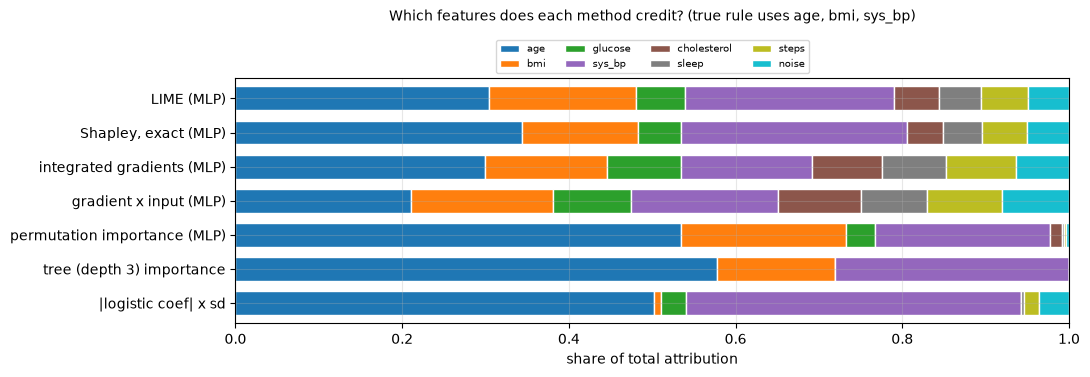

share of attribution on the three truly used features:
|logistic coef| x sd            0.912
tree (depth 3) importance       1.000
permutation importance (MLP)    0.942
gradient x input (MLP)          0.558
integrated gradients (MLP)      0.602
Shapley, exact (MLP)            0.755
LIME (MLP)                      0.731

MLP: mean |Shapley| of the decoy 'glucose' = 0.23 logit units, versus 0.65 for 'bmi'

Patient 39: model logit -17.45, average logit -0.58
             value (sd units)  Shapley   LIME     IG
age                     -1.96    -9.59 -14.15 -12.73
bmi                      2.45    -4.85  -6.61  -4.20
glucose                  2.03     0.23   0.31   1.26
sys_bp                  -0.46    -1.30  -1.41  -1.76
cholesterol             -0.26    -0.27  -0.19  -0.04
sleep                   -1.18    -1.03  -1.44  -0.53
steps                    1.85     0.27   1.04   1.73
noise                    0.58    -0.34  -0.15  -0.63


In [5]:
# Global comparison: mean |attribution| per feature for each method, scaled to sum to 1, against the known rule
glob = {
    "|logistic coef| x sd": np.abs(lr.coef_[0]) * sd,
    "tree (depth 3) importance": tree.feature_importances_,
    "permutation importance (MLP)": np.clip(perm, 0, None),
    "gradient x input (MLP)": np.abs(gxi).mean(0),
    "integrated gradients (MLP)": np.abs(ig).mean(0),
    "Shapley, exact (MLP)": np.abs(shap_vals).mean(0),
    "LIME (MLP)": np.abs(lime).mean(0),
}
G = pd.DataFrame({k: v / v.sum() for k, v in glob.items()}, index=FEATS)
fig, ax = plt.subplots(figsize=(11, 4))
G.T.plot.barh(stacked=True, ax=ax, width=0.7, colormap="tab10", edgecolor="white")
ax.set_xlabel("share of total attribution"); ax.legend(ncol=4, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("Which features does each method credit? (true rule uses age, bmi, sys_bp)", y=1.2, fontsize=10); plt.tight_layout(); plt.show()

mass = G.loc[[FEATS[i] for i in USED]].sum().round(3)
print("share of attribution on the three truly used features:")
print(mass.to_string())
print(f"\nMLP: mean |Shapley| of the decoy 'glucose' = {np.abs(shap_vals[:, 2]).mean():.2f} logit units, versus {np.abs(shap_vals[:, 1]).mean():.2f} for 'bmi'")

# one patient, explained locally
i = int(np.argmax(np.abs(fx_v - base_v)))
local = pd.DataFrame({"value (sd units)": EVAL[i], "Shapley": shap_vals[i], "LIME": lime[i], "IG": ig[i]}, index=FEATS).round(2)
print(f"\nPatient {i}: model logit {fx_v[i]:.2f}, average logit {base_v[i]:.2f}")
print(local.to_string())

**Reading.** First the checks. Exact Shapley values satisfy completeness to 7e-7 and reproduce the linear-model formula to 6e-8, so our implementation is right. Integrated gradients with 64 steps is complete to within 0.10 logit units (the scores reach 17 in size), whereas gradient times input is off by up to 9: the first-order approximation is not an attribution of the whole score. The Monte Carlo Shapley error falls from 0.42 with 10 sampled orders to 0.019 with 5000, roughly one over the square root of the number of orders, which is why it is the route for models with many features. On this machine the optional `shap.KernelExplainer` comparison ran and its largest difference from our exact values was 0.21 on five inputs, a sampling error of the same size as our Monte Carlo at about 50 orders; if `shap` is not installed the cell prints a message instead. LIME is stable across random seeds (rank correlation 0.96) but its agreement with Shapley depends on the kernel width we chose (0.45 at width 0.5, 0.58 at width 1, 0.60 at 2 and 0.62 at 4): a narrow neighbourhood gives a different, more local, answer, not a wrong one.

Now the global comparison. The readable models and permutation importance put 91 to 100 % of the credit on the three features that the rule really uses (logistic regression 0.91, tree 1.00, permutation importance 0.94). The local methods on the MLP put less: Shapley 0.76, LIME 0.73, integrated gradients 0.60, gradient times input 0.56. Where does the rest go? The MLP was trained for 600 steps on 4500 rows and it fitted some noise, so it genuinely responds to `sleep`, `steps` and `noise` (patient 39 in the table: sleep contributes about -1 logit unit). The attribution is faithful to the **model**, which is not the same as the **truth**. Permutation importance on held-out data averages such noise away, which is why it looks cleaner. In the patient table the three methods agree on the sign and rank of the big contributors (age, then bmi) and differ by 20 to 50 % in magnitude: the numbers are method-specific, the story is shared. Single trained model, 150 test inputs.

In [6]:
# Explanation is not a causal claim: intervene on the real mechanism and on the model
r = np.random.default_rng(5)
n = 4000
age_i, bmi_i, bp_i = r.normal(size=n), r.normal(size=n), r.normal(size=n)
def build(glu, bmi_v):
    return np.column_stack([age_i, bmi_v, glu, bp_i, r.normal(size=n), r.normal(size=n), r.normal(size=n), r.normal(size=n)]).astype(np.float32)
glu0 = 0.8 * bmi_i + 0.6 * r.normal(size=n)
base_X = build(glu0, bmi_i)
true_rule = lambda a, b, p: 1 / (1 + np.exp(-(1.4 * a + 1.0 * p + 1.2 * a * b - 0.2)))
p0 = true_rule(age_i, bmi_i, bp_i).mean()
# do(glucose = glucose + 1 sd): in the real mechanism glucose has no effect, so the true risk cannot move
print(f"true mean risk {p0:.3f}; after setting glucose +1 sd the TRUE risk is still {true_rule(age_i, bmi_i, bp_i).mean():.3f} (the rule ignores glucose)")
p_model = 1 / (1 + np.exp(-f_mlp(base_X))); p_model_g = 1 / (1 + np.exp(-f_mlp(build(glu0 + 1.0, bmi_i))))
print(f"MLP mean risk {p_model.mean():.3f}; after glucose +1 sd the MODEL says {p_model_g.mean():.3f}  (change {p_model_g.mean() - p_model.mean():+.3f})")

true mean risk 0.475; after setting glucose +1 sd the TRUE risk is still 0.475 (the rule ignores glucose)
MLP mean risk 0.482; after glucose +1 sd the MODEL says 0.509  (change +0.027)


**Reading.** The real mechanism ignores `glucose`, so setting it one standard deviation higher leaves the true mean risk at exactly 0.475. The MLP, which learned to use `glucose` as a partly redundant proxy for `bmi` (mean absolute Shapley value 0.23 logit units, against 0.65 for `bmi`), raises its mean prediction from 0.482 to 0.509, a 2.7-point change that does not exist in the world. The attribution was correct about the model and would have been misleading as advice ("lower glucose to lower risk"). To say what changes the outcome you need an experiment, a causal model, or at least domain knowledge; an explanation of a predictive model supplies none of these. One model, one seed, but the direction is guaranteed by construction here.

## 4. Vision: attribution maps, Grad-CAM, sanity checks and deletion curves

For images an attribution is a map over pixels. We train a small CNN (three convolution layers, global average pooling, a linear head) on **Fashion-MNIST** (Xiao et al., [2017](https://arxiv.org/abs/1708.07747); [dataset card](https://huggingface.co/datasets/zalando-datasets/fashion_mnist), MIT licence, cached from the Hugging Face Hub): 28 by 28 grey images of ten clothing classes. We use 8000 training and 1000 test images. For an image $x$ and class $c$, let $f_c(x)$ be the network's score (logit) for $c$. The maps are:

* **Saliency** (Simonyan et al., [2014](https://arxiv.org/abs/1312.6034)): $|\partial f_c/\partial x|$, how sensitive the score is to each pixel.
* **SmoothGrad** (Smilkov et al., [2017](https://arxiv.org/abs/1706.03825)): average the gradient over many noisy copies of the image to remove the speckle.
* **Integrated gradients** against a black image, as in section 3.
* **Grad-CAM** (Selvaraju et al., [2017](https://arxiv.org/abs/1610.02391)): take the last convolutional feature maps $A^k$ ($k$ indexes channels), weight each by the average gradient of the score with respect to it, $\alpha_k = \frac{1}{HW}\sum_{u,v} \partial f_c/\partial A^k_{uv}$, sum, keep the positive part, and upsample: $\text{Grad-CAM} = \text{ReLU}\big(\sum_k \alpha_k A^k\big)$. It is coarse (the feature map is 7 by 7 here) but shows *regions*.

In [7]:
from huggingface_hub import hf_hub_download
from PIL import Image

FM_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
def fm_split(split, n, seed):
    df = pd.read_parquet(hf_hub_download("zalando-datasets/fashion_mnist", f"fashion_mnist/{split}-00000-of-00001.parquet", repo_type="dataset"))
    idx = np.random.default_rng(seed).permutation(len(df))[:n]
    x = np.stack([np.array(Image.open(io.BytesIO(df.image.iloc[i]["bytes"]))) for i in idx]).astype(np.float32) / 255
    return torch.from_numpy(x).unsqueeze(1), torch.tensor(df.label.values[idx])
Xi_tr, yi_tr = fm_split("train", 8000, 0)
Xi_te, yi_te = fm_split("test", 1000, 1)
print("train", tuple(Xi_tr.shape), "test", tuple(Xi_te.shape))

class SmallCNN(nn.Module):
    def __init__(s):
        super().__init__()
        s.c1, s.c2, s.c3 = nn.Conv2d(1, 16, 3, padding=1), nn.Conv2d(16, 32, 3, padding=1), nn.Conv2d(32, 64, 3, padding=1)
        s.fc = nn.Linear(64, 10)
    def features(s, x):                                   # last convolutional maps A, shape (n, 64, 7, 7)
        x = F.max_pool2d(F.relu(s.c1(x)), 2)
        x = F.max_pool2d(F.relu(s.c2(x)), 2)
        return F.relu(s.c3(x))
    def forward(s, x): return s.fc(s.features(x).mean((2, 3)))

def train_cnn(Xa, ya, epochs=7, seed=0):
    torch.manual_seed(seed); m = SmallCNN(); opt = torch.optim.Adam(m.parameters(), 3e-3)
    for ep in range(epochs):
        perm = torch.randperm(len(Xa))
        for i in range(0, len(Xa), 128):
            b = perm[i:i + 128]; loss = F.cross_entropy(m(Xa[b]), ya[b]); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

@torch.no_grad()
def accuracy(m, Xa, ya): return float((m(Xa).argmax(1) == ya).float().mean())

t0 = time.time(); cnn = train_cnn(Xi_tr, yi_tr)
print(f"small CNN trained in {time.time() - t0:.0f} s; test accuracy {accuracy(cnn, Xi_te, yi_te):.3f}")

train (8000, 1, 28, 28) test (1000, 1, 28, 28)


small CNN trained in 10 s; test accuracy 0.742


IG completeness on images: max |sum(IG) - (f(x) - f(black))| = 0.284  (scores are of size 8.6)


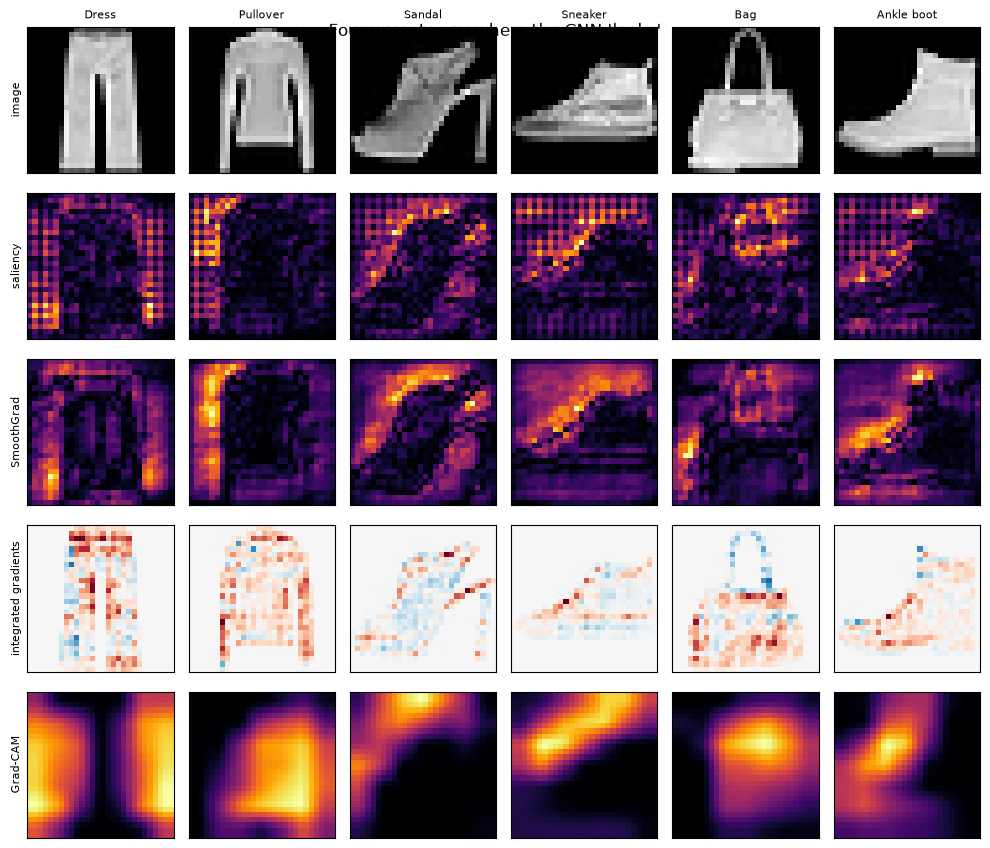

mean per-image rank correlation between methods (60 images):
                      saliency  SmoothGrad  integrated gradients  Grad-CAM
saliency                  1.00        0.63                 -0.08      0.08
SmoothGrad                0.63        1.00                 -0.20      0.04
integrated gradients     -0.08       -0.20                  1.00     -0.02
Grad-CAM                  0.08        0.04                 -0.02      1.00


In [8]:
def _target_score(m, x, c): return m(x).gather(1, c[:, None]).sum()

def saliency_map(m, x, c):
    x = x.clone().requires_grad_(True); _target_score(m, x, c).backward(); return x.grad.detach()

def smoothgrad_map(m, x, c, n=25, sigma=0.15, seed=0):
    g = torch.Generator().manual_seed(seed); tot = torch.zeros_like(x)
    for _ in range(n): tot += saliency_map(m, x + sigma * torch.randn(x.shape, generator=g), c)
    return tot / n

def ig_map(m, x, c, steps=32, baseline=None):
    b = torch.zeros_like(x) if baseline is None else baseline; tot = torch.zeros_like(x)
    for k in range(steps): tot += saliency_map(m, b + (k + 0.5) / steps * (x - b), c)
    return tot / steps * (x - b)

def gradcam_map(m, x, c):
    A = m.features(x).detach().requires_grad_(True)
    m.fc(A.mean((2, 3))).gather(1, c[:, None]).sum().backward()
    w = A.grad.mean((2, 3), keepdim=True)
    cam = F.relu((w * A.detach()).sum(1, keepdim=True))
    return F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)

xs, ys = Xi_te[:200], yi_te[:200]
pred = cnn(xs).argmax(1)
# completeness check for integrated gradients on the CNN: sum(IG) should equal f_c(x) - f_c(black image)
ig_chk = ig_map(cnn, xs[:20], pred[:20], steps=64).sum((1, 2, 3))
with torch.no_grad(): ig_gap = (cnn(xs[:20]).gather(1, pred[:20, None])[:, 0] - cnn(torch.zeros_like(xs[:20])).gather(1, pred[:20, None])[:, 0])
print(f"IG completeness on images: max |sum(IG) - (f(x) - f(black))| = {(ig_chk - ig_gap).abs().max():.3f}  (scores are of size {ig_gap.abs().mean():.1f})")

maps = {"saliency": saliency_map(cnn, xs, pred).abs(), "SmoothGrad": smoothgrad_map(cnn, xs, pred).abs(),
        "integrated gradients": ig_map(cnn, xs, pred), "Grad-CAM": gradcam_map(cnn, xs, pred)}
show = [int(np.where(ys.numpy() == c)[0][0]) for c in [1, 2, 5, 7, 8, 9]]
fig, axes = plt.subplots(5, 6, figsize=(10, 9))
for j, i in enumerate(show):
    axes[0, j].imshow(xs[i, 0], cmap="gray"); axes[0, j].set_title(f"{FM_NAMES[pred[i]]}", fontsize=8)
    for r_, (name, mp) in enumerate(maps.items(), start=1):
        v = mp[i, 0].numpy(); lim = np.abs(v).max() + 1e-9
        axes[r_, j].imshow(v, cmap="RdBu_r" if name == "integrated gradients" else "inferno", vmin=-lim if name == "integrated gradients" else 0, vmax=lim)
        if j == 0: axes[r_, j].set_ylabel(name, fontsize=8)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
axes[0, 0].set_ylabel("image", fontsize=8); plt.suptitle("Four ways to say where the CNN 'looks'", y=0.93); plt.tight_layout(); plt.show()

# do the methods agree with one another? mean rank correlation of |maps| across images
names = list(maps); M = np.zeros((4, 4))
for a, b in itertools.product(range(4), range(4)):
    M[a, b] = np.mean([rank_corr(maps[names[a]][i].abs().flatten().numpy(), maps[names[b]][i].abs().flatten().numpy()) for i in range(60)])
print("mean per-image rank correlation between methods (60 images):")
print(pd.DataFrame(M, index=names, columns=names).round(2).to_string())

**Reading.** The CNN reaches only 0.742 test accuracy (8000 training images, 7 epochs, a global-average-pooling head): good enough to study, not a strong model, and weaker models give noisier maps. Integrated gradients is complete on images to within 0.28 score units (scores of size 8.6). The picture matters more than the numbers: the four methods produce visibly different maps for the same image and prediction. The per-image rank correlation between saliency and SmoothGrad is 0.63 (the second is a denoised version of the first), but integrated gradients correlates at -0.08 to -0.20 with them and Grad-CAM at 0.02 to 0.08 with everything. Some of that is by design (integrated gradients is signed and multiplies by the image; Grad-CAM is a 7 by 7 map upsampled), but it shows that "the model's attention map" is not one object. Which one should you believe? The next two tests are how we decide.

### 4.1 Sanity check: do the maps depend on the model?

Adebayo et al. ([2018](https://arxiv.org/abs/1810.03292)) proposed a test any explanation method should pass: **randomise the model's weights and the explanation should change**. If a method gives nearly the same picture for a trained network and for a network with random weights, then the picture is telling us about the *image* (edges, contrast), not about what the network learned. They randomise layer by layer, from the top (the linear head) down to the first convolution ("cascading randomisation"). We measure the rank correlation between each method's map on the trained model and on the progressively destroyed one, and add a **model-free control**: a Sobel edge detector, which by construction cannot depend on any model. A method that stays close to the edge detector's behaviour fails the test.

              saliency  integrated gradients  Grad-CAM
trained           1.00                  1.00      1.00
fc random         0.37                  0.88      0.08
+ c3 random       0.32                  0.88      0.05
+ c2 random       0.11                  0.87      0.08
+ all random      0.03                  0.87      0.13


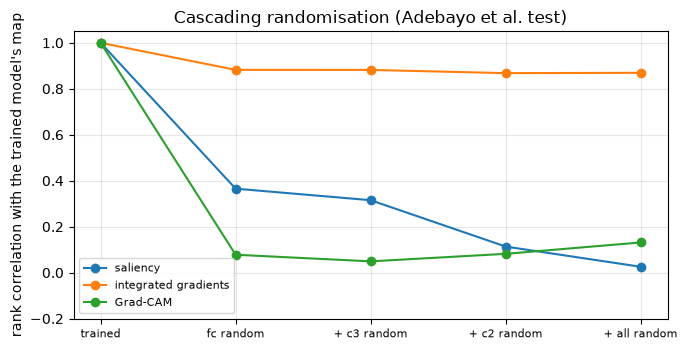

                      after full randomisation  corr with Sobel edges, trained  corr with Sobel edges, randomised
saliency                                  0.03                           -0.07                               0.20
integrated gradients                      0.87                            0.55                               0.54
Grad-CAM                                  0.13                            0.01                               0.10


accuracy of the fully randomised network: 0.089 (chance is 0.100)


In [9]:
import copy
from scipy import ndimage

def randomise(m, upto, seed=123):
    # re-initialise layers from the top: 'fc', then also c3, c2, c1
    m2 = copy.deepcopy(m); order = ["fc", "c3", "c2", "c1"]; torch.manual_seed(seed)
    for name in order[:upto]:
        layer = getattr(m2, name); layer.reset_parameters()
    return m2.eval()

xs100, pred100 = xs[:100], pred[:100]
def edge_map(x):
    return torch.tensor(np.stack([np.hypot(ndimage.sobel(a[0], 0), ndimage.sobel(a[0], 1)) for a in x.numpy()]))[:, None]

methods = {"saliency": lambda m: saliency_map(m, xs100, pred100).abs(),
           "integrated gradients": lambda m: ig_map(m, xs100, pred100, steps=16).abs(),
           "Grad-CAM": lambda m: gradcam_map(m, xs100, pred100)}
orig = {k: f(cnn) for k, f in methods.items()}
stages = ["trained", "fc random", "+ c3 random", "+ c2 random", "+ all random"]
res = {k: [1.0] for k in methods}
for upto in range(1, 5):
    mr = randomise(cnn, upto)
    for k, f in methods.items():
        mp = f(mr)
        res[k].append(np.mean([rank_corr(orig[k][i].flatten().numpy(), mp[i].flatten().numpy()) for i in range(100)]))
edges = edge_map(xs100)
edge_corr = {k: np.mean([rank_corr(orig[k][i].flatten().numpy(), edges[i].flatten().numpy()) for i in range(100)]) for k in methods}
# how much do the maps of the randomised network look like an edge detector? (for saliency and IG)
mr_all = randomise(cnn, 4)
edge_rand = {k: np.mean([rank_corr(f(mr_all)[i].flatten().numpy(), edges[i].flatten().numpy()) for i in range(100)]) for k, f in methods.items()}

print(pd.DataFrame(res, index=stages).round(2).to_string())
fig, ax = plt.subplots(figsize=(7, 3.6))
for k in methods: ax.plot(stages, res[k], "o-", label=k)
ax.set_ylabel("rank correlation with the trained model's map"); ax.set_ylim(-0.2, 1.05); ax.tick_params(axis="x", labelsize=8)
ax.set_title("Cascading randomisation (Adebayo et al. test)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(pd.DataFrame({"after full randomisation": {k: res[k][-1] for k in methods},
                    "corr with Sobel edges, trained": edge_corr, "corr with Sobel edges, randomised": edge_rand}).round(2).to_string())
print("accuracy of the fully randomised network:", f"{accuracy(mr_all, Xi_te, yi_te):.3f}", "(chance is 0.100)")

**Reading.** Saliency and Grad-CAM pass: saliency falls to a correlation of 0.37 with the trained map once only the linear head is re-initialised, and to 0.03 when all layers are random; Grad-CAM drops to 0.08 at the first step and ends at 0.13. **Integrated gradients fails in this form**: its correlation with its trained self stays at 0.88, 0.88, 0.87 and 0.87 while the network goes from 74 % accuracy to chance (0.089). The map of a random network also has a rank correlation of 0.54 with a Sobel edge detector, almost the same as the trained one (0.55). Two reasons, both known: integrated gradients multiplies the gradient by the image (here a black baseline), so wherever the image is zero the map is zero for any network, and the many zero background pixels agree trivially; and a random convolutional network still responds to edges. This is exactly what Adebayo et al. warned about for methods that multiply by the input. It does not mean integrated gradients is useless (next section), only that **its picture alone does not show what the network learned**. We used 100 images, one randomisation seed, and rank correlation over all pixels, which is the crudest of the measures in the paper.

### 4.2 Faithfulness: delete what the map points at

A map is **faithful** if removing the pixels it ranks highest damages the prediction more than removing pixels at random. The **deletion curve** (Samek et al., [2017](https://arxiv.org/abs/1509.06321); Petsiuk et al., [2018](https://arxiv.org/abs/1806.07421)) sets the top-$k$ pixels to black for growing $k$ and tracks the probability of the originally predicted class; a *lower area under the curve* means a more faithful ranking. We add two honest controls: **random** order (the floor) and **brightness** (delete the brightest pixels first, a model-free ranking). Deleting by setting pixels to black takes images off the training distribution, which is a known weakness of this test; we come back to it in section 9.

deletion AUC (area under the curve of probability vs pixels deleted, lower is more faithful):
integrated gradients       0.231
brightness (model-free)    0.388
Grad-CAM                   0.584
SmoothGrad                 0.611
saliency                   0.617
random                     0.620


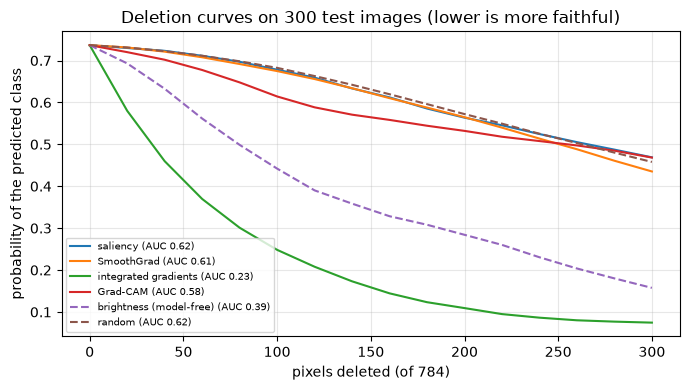

In [10]:
def deletion_curve(m, x, c, scores, ks):
    n = len(x); rank = scores.reshape(n, -1).argsort(1, descending=True); out = []
    for k in ks:
        xd = x.reshape(n, -1).clone(); xd.scatter_(1, rank[:, :k], 0.0)
        with torch.no_grad(): p = F.softmax(m(xd.reshape(x.shape)), 1).gather(1, c[:, None])[:, 0]
        out.append(float(p.mean()))
    return np.array(out)

ks = list(range(0, 301, 20))
xe, ce = Xi_te[:300], cnn(Xi_te[:300]).argmax(1)
scores = {"saliency": saliency_map(cnn, xe, ce).abs(), "SmoothGrad": smoothgrad_map(cnn, xe, ce).abs(),
          "integrated gradients": ig_map(cnn, xe, ce), "Grad-CAM": gradcam_map(cnn, xe, ce),
          "brightness (model-free)": xe.clone()}
g = torch.Generator().manual_seed(0)
curves = {k: deletion_curve(cnn, xe, ce, s, ks) for k, s in scores.items()}
curves["random"] = np.mean([deletion_curve(cnn, xe, ce, torch.rand(xe.shape, generator=g), ks) for _ in range(5)], 0)
auc = {k: np.trapezoid(v, ks) / ks[-1] for k, v in curves.items()}

print("deletion AUC (area under the curve of probability vs pixels deleted, lower is more faithful):")
print(pd.Series(auc).round(3).sort_values().to_string())
fig, ax = plt.subplots(figsize=(7, 4))
for k, v in curves.items(): ax.plot(ks, v, label=f"{k} (AUC {auc[k]:.2f})", ls="--" if k in ("random", "brightness (model-free)") else "-")
ax.set_xlabel("pixels deleted (of 784)"); ax.set_ylabel("probability of the predicted class"); ax.legend(fontsize=7)
ax.set_title("Deletion curves on 300 test images (lower is more faithful)"); plt.tight_layout(); plt.show()

**Reading.** Integrated gradients has by far the lowest area (0.231), better than the model-free brightness ranking (0.388). Grad-CAM (0.584) is a little better than random (0.620), and **plain saliency (0.617) and SmoothGrad (0.611) are no better than random** at this deletion test. So the two tests disagree: integrated gradients failed the sanity check but is the most faithful by deletion, saliency passed the sanity check but is not faithful by deletion. Passing one test does not imply passing the other, because they measure different things: sensitivity of the output to small changes (gradients, which saturate for networks with ReLU units and a pooled head) versus the effect of removing evidence (which integrated gradients, by its path from black to the image, is built to track). Part of integrated gradients' win is that it ranks bright, positively contributing pixels first and removing them is also a strong perturbation, and the brightness control shows how far a model-free ranking already gets. 300 test images and one model; differences below about 0.02 should not be interpreted.

## 5. A planted shortcut: can attribution find it?

Debugging is the most practical use of interpretability, so we test it on a flaw we create. We plant a **watermark**: a $4 \times 4$ patch in the top-left corner (16 of 784 pixels, 2 % of the image) whose grey level **encodes the class**. In the training set the patch is always present and always correct, a perfect shortcut that is also *easier* to learn than the shape of a coat. Real versions of this are common: a hospital's scanner marker, a watermark in photographs of one class, a background colour that goes with a label.

We train a model on the watermarked data and test it three ways: with the watermark as in training (**cue on**), with the patch erased (**cue removed**), and with the patch showing a *wrong* class (**cue misleading**). The "clean" model of section 4 never saw the watermark and serves as the control. A third model trains with the patch present but **random** (decorrelated from the class), the standard remedy. To see whether attribution reveals the flaw we measure (i) the **share of attribution mass** inside the patch (a fair share would be 2 %) and (ii) the **pointing game** (Zhang et al., [2018](https://arxiv.org/abs/1608.00507)): the percentage of images where the single highest-attributed pixel lies in the patch.

trained the shortcut and the remedy models in 19 s


                             model  cue on  cue off  cue wrong
clean model (no patch in training)   0.678    0.743      0.698
    shortcut model (patch = label)   0.880    0.552      0.582
          remedy (patch is random)   0.754    0.768      0.762



integrated gradients on watermarked test images (a fair share of mass would be 0.02):
                                    clean  shortcut  remedy
share of |IG| mass in the patch     0.047     0.136   0.037
pointing game (top pixel in patch)  0.023     0.453   0.017


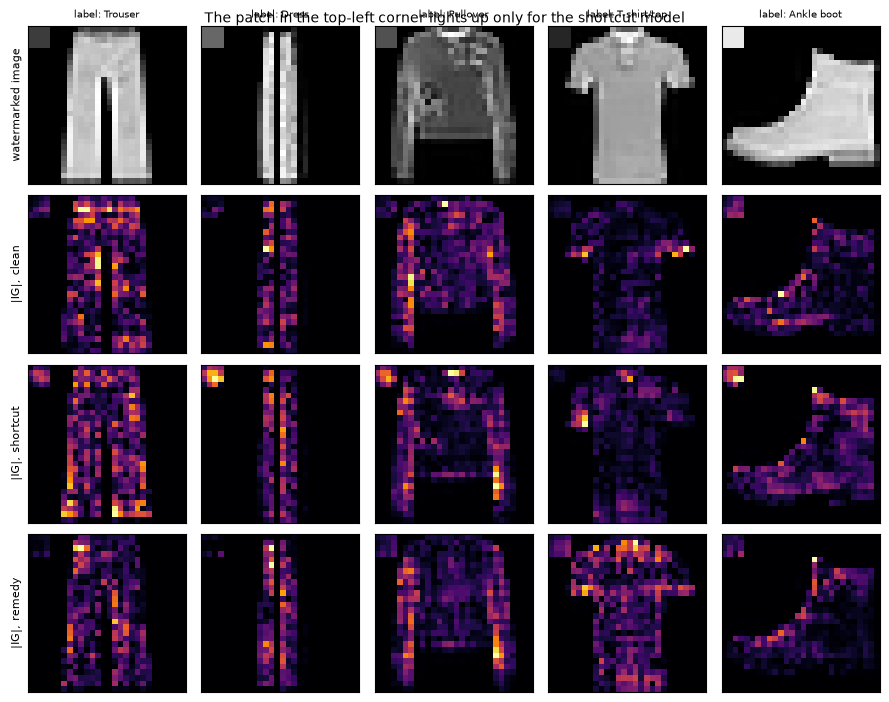

In [11]:
def cue_levels(y): return 0.15 + 0.085 * y.float()                  # grey level that encodes the class
def with_cue(x, y, mode, seed=0):
    x = x.clone(); g = torch.Generator().manual_seed(seed)
    if mode == "off": lvl = torch.zeros(len(x))
    elif mode == "on": lvl = cue_levels(y)
    elif mode == "wrong": lvl = cue_levels((y + torch.randint(1, 10, (len(y),), generator=g)) % 10)
    elif mode == "random": lvl = cue_levels(torch.randint(0, 10, (len(y),), generator=g))
    x[:, 0, :4, :4] = lvl[:, None, None]
    return x

t0 = time.time()
cue_model = train_cnn(with_cue(Xi_tr, yi_tr, "on"), yi_tr, seed=1)
fixed_model = train_cnn(with_cue(Xi_tr, yi_tr, "random", seed=7), yi_tr, seed=2)
print(f"trained the shortcut and the remedy models in {time.time() - t0:.0f} s")

rows = []
for name, m in [("clean model (no patch in training)", cnn), ("shortcut model (patch = label)", cue_model), ("remedy (patch is random)", fixed_model)]:
    rows.append({"model": name, **{f"cue {mode}": accuracy(m, with_cue(Xi_te, yi_te, mode), yi_te) for mode in ["on", "off", "wrong"]}})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# attribution: where does integrated gradients put its mass for the three models, on the 'cue on' test images?
xc, yc = with_cue(Xi_te[:300], yi_te[:300], "on"), yi_te[:300]
def patch_stats(m):
    p = m(xc).argmax(1); a = ig_map(m, xc, p, steps=16).abs()[:, 0]
    mass = a[:, :4, :4].sum((1, 2)) / a.sum((1, 2)); top = a.flatten(1).argmax(1); inside = ((top // 28) < 4) & ((top % 28) < 4)
    return float(mass.mean()), float(inside.float().mean()), a
stats = {n: patch_stats(m) for n, m in [("clean", cnn), ("shortcut", cue_model), ("remedy", fixed_model)]}
print("\nintegrated gradients on watermarked test images (a fair share of mass would be 0.02):")
print(pd.DataFrame({n: {"share of |IG| mass in the patch": s[0], "pointing game (top pixel in patch)": s[1]} for n, s in stats.items()}).round(3).to_string())

fig, axes = plt.subplots(4, 5, figsize=(9, 7.4))
for j, i in enumerate([0, 3, 5, 8, 11]):
    axes[0, j].imshow(xc[i, 0], cmap="gray"); axes[0, j].set_title(f"label: {FM_NAMES[yc[i]]}", fontsize=7)
    for r_, n in enumerate(["clean", "shortcut", "remedy"], start=1):
        axes[r_, j].imshow(stats[n][2][i], cmap="inferno")
        if j == 0: axes[r_, j].set_ylabel(f"|IG|, {n}", fontsize=8)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([]); a.grid(False)
axes[0, 0].set_ylabel("watermarked image", fontsize=8); plt.suptitle("The patch in the top-left corner lights up only for the shortcut model", y=0.94, fontsize=10); plt.tight_layout(); plt.show()

**Reading.** The shortcut worked as designed. On watermarked test images the shortcut model scores 0.880, more than the clean model (0.678, which has never seen the patch). When the patch is erased its accuracy falls by 33 points to 0.552, and when the patch shows the wrong class it falls to 0.582: it is using the corner as well as the clothing, because 0.55 is still far above chance. The clean model barely cares (0.678 to 0.743 to 0.698, within noise of a single model on 1000 images) and the remedy, trained with a random patch, is flat across the three conditions (0.754, 0.768, 0.762), as a model that was forced to ignore the patch should be. Attribution found the flaw: for the shortcut model the top integrated-gradient pixel lies in the 4 by 4 patch in 45 % of the test images (2 % of the pixels), against 2 % for the clean model and 2 % for the remedy; the patch carries 13.6 % of the attribution mass against 4.7 % and 3.7 %. Two cautions. Attribution said "the patch matters", not "the patch is a cheat"; deciding that needed our knowledge of how the data was made, and removing the cue to measure the accuracy drop is the real evidence. And the pointing game found it in under half of the images, because the model also uses the garment: the absence of a bright spot would not have proved the absence of a shortcut. Single seed per model.

## 6. Grad-CAM on a pre-trained ResNet-18

Training a large network from scratch is out of reach on a CPU, so for a real model we use the ImageNet-trained **ResNet-18** of He et al. ([2015](https://arxiv.org/abs/1512.03385)) from `torchvision` (weights `IMAGENET1K_V1`, cached; the code is BSD-3 licensed and the weights were trained on ImageNet, whose [terms](https://www.image-net.org/download.php) restrict use to non-commercial research and education; [model documentation](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)). Grad-CAM uses the last residual stage (`layer4`, a 7 by 7 grid). The photographs come bundled with scikit-image ([documentation](https://scikit-image.org/docs/stable/api/skimage.data.html); the cat and the coffee cup are CC0, the astronaut and the rocket are NASA images in the public domain). We take four photographs, three crops of each (12 images), and run a **deletion test on $14 \times 14$ pixel patches** (a $16 \times 16$ grid), comparing Grad-CAM with plain saliency and with random patches. The toy differs from real practice in scale: one small network and a dozen images, enough to see the method work but not to rank methods in general.

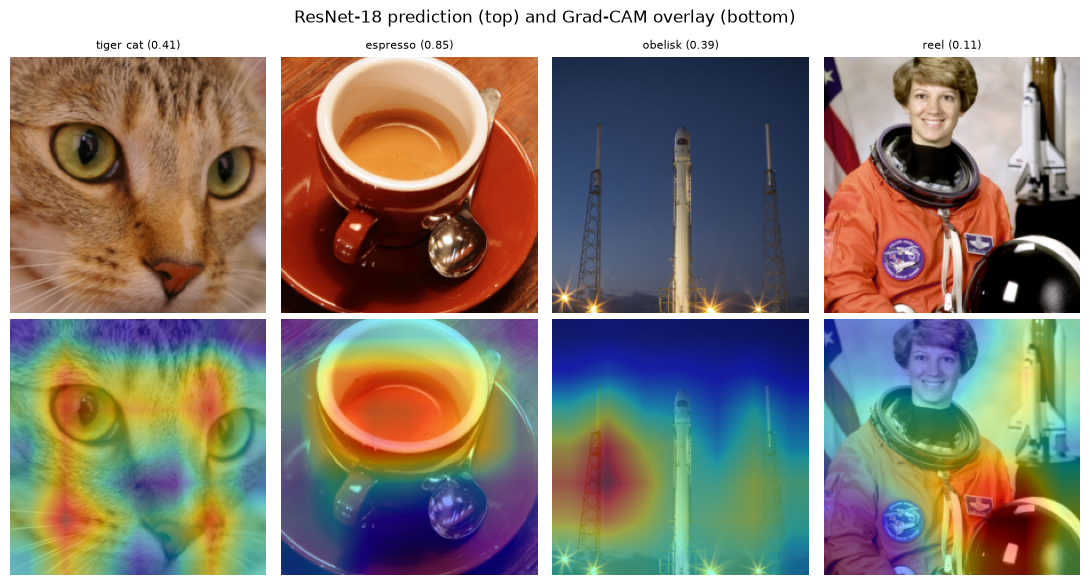

ResNet-18 predictions: ['tiger cat (0.41)', 'Egyptian cat (0.44)', 'Egyptian cat (0.68)', 'espresso (0.85)', 'espresso (0.86)', 'espresso (0.81)', 'obelisk (0.39)', 'obelisk (0.42)', 'missile (0.36)', 'reel (0.11)', 'stethoscope (0.36)', 'stethoscope (0.17)']
deletion AUC: {'Grad-CAM': 0.162, 'saliency': 0.135, 'random': 0.121}
probability of the predicted class after deleting 96 patches (37 %): {'Grad-CAM': 0.043, 'saliency': 0.023, 'random': 0.001}


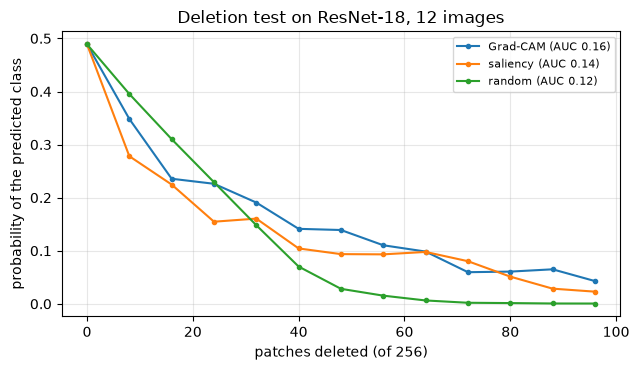

In [12]:
import torchvision
from skimage import data as skdata

W = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
rn = torchvision.models.resnet18(weights=W).eval()
CATS = W.meta["categories"]
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def crops(img, n=3, seed=0):
    im = Image.fromarray(img); w, h = im.size; s = 256 / min(w, h)
    im = np.array(im.resize((round(w * s), round(h * s)), Image.BILINEAR)); H_, W_ = im.shape[:2]
    r = np.random.default_rng(seed); out = [im[(H_ - 224) // 2:(H_ - 224) // 2 + 224, (W_ - 224) // 2:(W_ - 224) // 2 + 224]]
    for _ in range(n - 1):
        y0, x0 = r.integers(0, H_ - 223), r.integers(0, W_ - 223); out.append(im[y0:y0 + 224, x0:x0 + 224])
    return out
photos = {"chelsea": skdata.chelsea(), "coffee": skdata.coffee(), "rocket": skdata.rocket(), "astronaut": skdata.astronaut()}
raw = [c for k, v in photos.items() for c in crops(v, 3, seed=len(k))]
xr = (torch.from_numpy(np.stack(raw)).permute(0, 3, 1, 2).float() / 255 - MEAN) / STD

def resnet_cam(x, c=None):
    store = {}; h = rn.layer4.register_forward_hook(lambda m, i, o: store.__setitem__("A", o))
    logits = rn(x); h.remove(); A = store["A"]
    c = logits.argmax(1) if c is None else c
    g = torch.autograd.grad(logits.gather(1, c[:, None]).sum(), A)[0]
    cam = F.relu((g.mean((2, 3), keepdim=True) * A).sum(1, keepdim=True)).detach()
    return F.interpolate(cam, size=224, mode="bilinear", align_corners=False)[:, 0], c, F.softmax(logits, 1).detach()

def resnet_saliency(x, c):
    x = x.clone().requires_grad_(True); rn(x).gather(1, c[:, None]).sum().backward(); return x.grad.abs().amax(1)

cam, cls, probs = resnet_cam(xr)
sal = resnet_saliency(xr, cls)
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for j, i in enumerate([0, 3, 6, 9]):
    axes[0, j].imshow(raw[i]); axes[0, j].set_title(f"{CATS[cls[i]]} ({probs[i, cls[i]]:.2f})", fontsize=8)
    axes[1, j].imshow(raw[i]); axes[1, j].imshow(cam[i], cmap="jet", alpha=0.45)
for a in axes.ravel(): a.axis("off"); a.grid(False)
plt.suptitle("ResNet-18 prediction (top) and Grad-CAM overlay (bottom)"); plt.tight_layout(); plt.show()

def patch_scores(m):                                         # mean of a (n,224,224) map in each 14x14 patch -> (n, 256)
    return F.avg_pool2d(m[:, None], 14).flatten(1)

def patch_deletion(x, c, pscore, ks):
    rank = pscore.argsort(1, descending=True); out = []
    for k in ks:
        keep = torch.ones(len(x), 256); keep.scatter_(1, rank[:, :k], 0.0)
        mask = F.interpolate(keep.view(-1, 1, 16, 16), size=224, mode="nearest")
        with torch.no_grad(): p = F.softmax(rn(x * mask), 1).gather(1, c[:, None])[:, 0]       # deleted patches become the mean colour
        out.append(float(p.mean()))
    return np.array(out)

ksr = list(range(0, 97, 8)); gr = torch.Generator().manual_seed(0)
rc = {"Grad-CAM": patch_deletion(xr, cls, patch_scores(cam), ksr), "saliency": patch_deletion(xr, cls, patch_scores(sal), ksr),
      "random": np.mean([patch_deletion(xr, cls, torch.rand(len(xr), 256, generator=gr), ksr) for _ in range(5)], 0)}
print("ResNet-18 predictions:", [f"{CATS[int(c)]} ({float(probs[i, int(c)]):.2f})" for i, c in enumerate(cls)])
print("deletion AUC:", {k: round(float(np.trapezoid(v, ksr) / ksr[-1]), 3) for k, v in rc.items()})
print("probability of the predicted class after deleting 96 patches (37 %):", {k: round(float(v[-1]), 3) for k, v in rc.items()})
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for k, v in rc.items(): ax.plot(ksr, v, "o-", ms=3, label=f"{k} (AUC {np.trapezoid(v, ksr) / ksr[-1]:.2f})")
ax.set_xlabel("patches deleted (of 256)"); ax.set_ylabel("probability of the predicted class"); ax.legend(fontsize=8)
ax.set_title("Deletion test on ResNet-18, 12 images"); plt.tight_layout(); plt.show()

**Reading.** Predictions are plausible for the cat (tiger cat 0.41 and Egyptian cat 0.44 and 0.68) and the coffee (espresso, 0.81 to 0.86), partly right for the rocket (obelisk 0.39 and 0.42, missile 0.36, reel 0.11) and wrong for the astronaut (stethoscope 0.36 and 0.17, ImageNet has no "astronaut" class and the model has to say something); the figure shows where Grad-CAM thinks the evidence is. The deletion test does **not** confirm Grad-CAM here: its area is 0.162, saliency 0.135 and random 0.121, so random patches hurt the prediction the most (after deleting 96 of 256 patches the probability is 0.043 for Grad-CAM, 0.023 for saliency and 0.001 for random). A plausible reason, which we did not test, is that random deletion spreads grey blocks over the whole image and breaks the textures the network relies on, while Grad-CAM deletes one contiguous region and the remaining context still supports the class; another is that the 7 by 7 Grad-CAM grid is coarse relative to a 14 pixel patch. Twelve images from four photographs is too few for a ranking of methods, but it is enough to show that a convincing heat map and a faithful ranking are different properties. The toy differs from practice in scale: practitioners evaluate on thousands of images with several network layers and fill strategies.

## 7. Language models: probes, and attention is not explanation

For text we use **DistilBERT** (Sanh et al., [2019](https://arxiv.org/abs/1910.01108); [model card](https://huggingface.co/distilbert/distilbert-base-uncased), Apache 2.0), a 66 million parameter encoder with 6 transformer layers, cached from the Hugging Face Hub, and **Banking77** (Casanueva et al., [2020](https://arxiv.org/abs/2003.04807); [dataset card](https://huggingface.co/datasets/PolyAI/banking77), CC BY 4.0): short customer questions labelled with an intent. We keep 8 intents chosen at random, 40 training and 25 test questions each. The language model of module 10 of Neural Networks 1001 is trained from scratch and is too small to carry real semantics; DistilBERT is the real thing at a size a CPU can handle.

### 7.1 Linear probes

A **probe** is a simple classifier trained on a model's frozen hidden states to test **what information is linearly readable** at each depth. We probe the mean of the token vectors at each of the 7 stops (the embedding layer and the 6 transformer layers). A probe only shows that information is *present*, not that the model *uses* it. Hewitt and Liang ([2019](https://arxiv.org/abs/1909.03368)) warn that a probe with enough capacity can learn the task by itself, so we add a **control task**: labels that depend on a random function of a word, which no representation "knows" but a 768-dimensional probe with 320 examples might memorise.

intents: ['apple_pay_or_google_pay', 'card_acceptance', 'exchange_via_app', 'fiat_currency_support', 'supported_cards_and_currencies', 'topping_up_by_card', 'verify_my_identity', 'visa_or_mastercard']
examples: google pay top up did not work | Do I get  a mastercard and visa?


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 9533.16it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


hidden states extracted in 6 s: train (320, 7, 768), test (200, 7, 768)


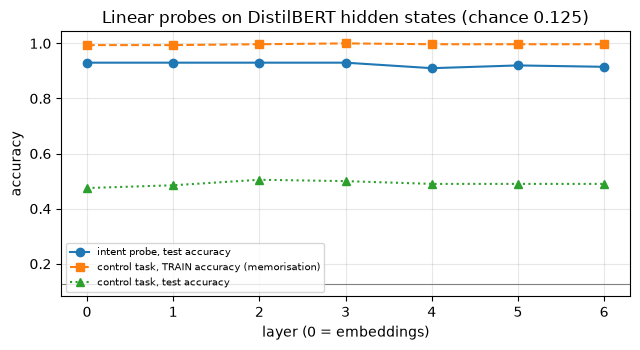

 layer  intent_test  control_train  control_test
     0        0.930          0.994         0.475
     1        0.930          0.994         0.485
     2        0.930          0.997         0.505
     3        0.930          1.000         0.500
     4        0.910          0.997         0.490
     5        0.920          0.997         0.490
     6        0.915          0.997         0.490


In [13]:
from transformers import AutoTokenizer, AutoModel
from huggingface_hub import DatasetCard
from sklearn.preprocessing import StandardScaler

tr_b = pd.read_parquet(hf_hub_download("PolyAI/banking77", "data/train-00000-of-00001.parquet", repo_type="dataset"))
te_b = pd.read_parquet(hf_hub_download("PolyAI/banking77", "data/test-00000-of-00001.parquet", repo_type="dataset"))
try:
    _nm = DatasetCard.load("PolyAI/banking77").data.to_dict()["dataset_info"]["features"][1]["dtype"]["class_label"]["names"]
    ALL_NAMES = list(_nm.values()) if isinstance(_nm, dict) else list(_nm)
    assert len(ALL_NAMES) == 77
except Exception:
    ALL_NAMES = [f"intent {i}" for i in range(77)]
rng = np.random.default_rng(1)
CLS = sorted(rng.choice(77, size=8, replace=False).tolist())
def take(df, per):
    parts = [df[df.label == c].sample(per, random_state=0) for c in CLS]
    d = pd.concat(parts).reset_index(drop=True); d["y"] = d.label.map({c: i for i, c in enumerate(CLS)}); return d
trb, teb = take(tr_b, 40), take(te_b, 25)
print("intents:", [ALL_NAMES[c] for c in CLS]); print("examples:", trb.text.iloc[0], "|", trb.text.iloc[-1])

tok = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")
bert = AutoModel.from_pretrained("distilbert/distilbert-base-uncased", attn_implementation="eager").eval()

@torch.no_grad()
def layer_means(texts, bs=64):
    outs = []
    for i in range(0, len(texts), bs):
        b = tok(texts[i:i + bs], return_tensors="pt", padding=True)
        hs = bert(**b, output_hidden_states=True).hidden_states               # 7 tensors (n, T, 768)
        m = b["attention_mask"][..., None].float()
        outs.append(torch.stack([(h * m).sum(1) / m.sum(1) for h in hs], 1))   # (n, 7, 768)
    return torch.cat(outs).numpy()
t0 = time.time()
Htr, Hte = layer_means(trb.text.tolist()), layer_means(teb.text.tolist())
print(f"hidden states extracted in {time.time() - t0:.0f} s: train {Htr.shape}, test {Hte.shape}")

def word_label(text, seed=0):      # control task: a fixed random class for the longest word of the sentence
    w = max(text.lower().split(), key=len); return int(np.random.default_rng(sum(map(ord, w)) + seed).integers(0, 8))
ctl_tr, ctl_te = np.array([word_label(t) for t in trb.text]), np.array([word_label(t) for t in teb.text])
rows = []
for l in range(7):
    sc = StandardScaler().fit(Htr[:, l])
    real = LogisticRegression(max_iter=500, C=0.05).fit(sc.transform(Htr[:, l]), trb.y)
    ctl = LogisticRegression(max_iter=500, C=0.05).fit(sc.transform(Htr[:, l]), ctl_tr)
    rows.append(dict(layer=l, intent_test=real.score(sc.transform(Hte[:, l]), teb.y), control_train=ctl.score(sc.transform(Htr[:, l]), ctl_tr),
                     control_test=ctl.score(sc.transform(Hte[:, l]), ctl_te)))
P = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(P.layer, P.intent_test, "o-", label="intent probe, test accuracy"); ax.plot(P.layer, P.control_train, "s--", label="control task, TRAIN accuracy (memorisation)")
ax.plot(P.layer, P.control_test, "^:", label="control task, test accuracy"); ax.axhline(1 / 8, color="grey", lw=0.8)
ax.set_xlabel("layer (0 = embeddings)"); ax.set_ylabel("accuracy"); ax.legend(fontsize=7); ax.set_title("Linear probes on DistilBERT hidden states (chance 0.125)"); plt.tight_layout(); plt.show()
print(P.round(3).to_string(index=False))

**Reading.** A linear probe on any of the seven stops identifies the intent of an unseen question with 0.91 to 0.93 accuracy, chance being 0.125, and the **embedding layer alone is already as good as the later layers** (0.930 at layers 0 to 3, 0.910 to 0.920 at layers 4 to 6, a difference of three to four test sentences out of 200). The eight intents differ by keywords ("visa", "identity", "exchange"), which the average of the word embeddings already captures, so this task cannot tell us where in the network the information appears. The control task shows why probes need care: with only 320 training examples a 768-dimensional probe memorises the random labels (train accuracy 0.99 to 1.00 at every layer), and its test accuracy of 0.48 to 0.51 is far above chance because the same long words recur in test sentences, so even the control is partly learnable from word identity. A probe shows that information is **linearly readable**, not that the model uses it, nor at which layer it was created.

### 7.2 Attention is not explanation

Transformer attention weights are easy to read out and look like an explanation: "the model attended to these words". Jain and Wallace ([2019](https://arxiv.org/abs/1902.10186)) showed that attention weights often correlate weakly with gradient-based importance and that very different attention can give the same output (Wiegreffe and Pinter, [2019](https://arxiv.org/abs/1908.04626), argue the question is subtler; both papers are worth reading). We measure it here. The classifier is the logistic regression on the **last layer mean** from 7.1, so the whole path from words to a decision is a differentiable function. For 40 test questions we compute three importance scores for every word piece:

* **attention**: the attention in the last layer, averaged over the 12 heads and over the query positions (how much the token is attended to);
* **gradient x input**: the absolute value of the gradient of the predicted class's score with respect to the token embedding, times the embedding, summed over dimensions;
* **occlusion**: replace the token with `[MASK]` and measure the drop in the predicted class's probability, the closest thing to a direct causal measurement here.

Then we **delete** the top-ranked token (replace it by `[MASK]`) according to each score and measure the drop in probability of the predicted class; random deletion is the control.

the classifier on the last layer: test accuracy 0.915


40 sentences analysed in 21 s; mean probability of the predicted class: 0.94

mean rank correlation between importance scores (per sentence, over real tokens):
attention vs gradient x input       -0.15
attention vs occlusion               0.04
attention from [CLS] vs occlusion   -0.23
gradient x input vs occlusion        0.39

mean drop in probability when the top-ranked token is replaced by [MASK]:
occlusion                 0.135
gradient x input          0.115
attention (last layer)    0.008
random                   -0.002
attention from [CLS]     -0.008


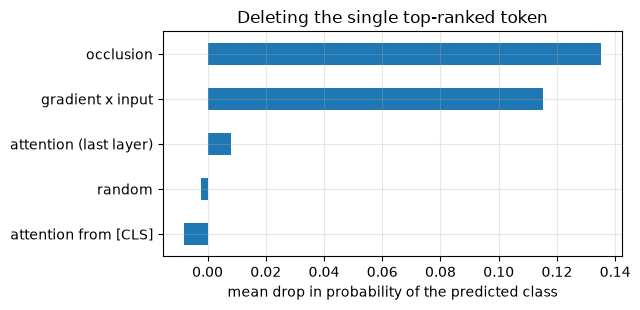

In [14]:
sc7 = StandardScaler().fit(Htr[:, 6])
clf7 = LogisticRegression(max_iter=500, C=0.05).fit(sc7.transform(Htr[:, 6]), trb.y)
Wc, bc = torch.tensor(clf7.coef_, dtype=torch.float32), torch.tensor(clf7.intercept_, dtype=torch.float32)
mu, sg = torch.tensor(sc7.mean_, dtype=torch.float32), torch.tensor(sc7.scale_, dtype=torch.float32)
print(f"the classifier on the last layer: test accuracy {clf7.score(sc7.transform(Hte[:, 6]), teb.y):.3f}")

def run(ids, mask, embeds=None, attn=False):
    emb = bert.embeddings.word_embeddings(ids) if embeds is None else embeds
    out = bert(inputs_embeds=emb, attention_mask=mask, output_attentions=attn)
    m = mask[..., None].float(); pooled = (out.last_hidden_state * m).sum(1) / m.sum(1)
    return ((pooled - mu) / sg) @ Wc.T + bc, out, emb

special = {tok.cls_token_id, tok.sep_token_id}
res_rows = []; per_sentence = []
t0 = time.time()
for text in teb.text.tolist()[:40]:
    b = tok(text, return_tensors="pt"); ids, mask = b["input_ids"], b["attention_mask"]
    real = [j for j in range(ids.shape[1]) if int(ids[0, j]) not in special]
    if len(real) < 4: continue
    emb = bert.embeddings.word_embeddings(ids).detach().requires_grad_(True)
    logits, out, _ = run(ids, mask, embeds=emb, attn=True)
    c = int(logits.argmax()); p0 = float(F.softmax(logits, 1)[0, c]); logits[0, c].backward()
    gi = (emb.grad * emb).abs().sum(-1)[0].detach().numpy()
    att = out.attentions[-1][0].mean(0).detach()                          # (T, T) averaged over heads
    ai = att.mean(0).numpy()                                              # attention RECEIVED, averaged over queries
    cls_row = att[0].numpy()                                              # attention FROM [CLS]
    occ = np.zeros(ids.shape[1])
    with torch.no_grad():
        for j in real:
            i2 = ids.clone(); i2[0, j] = tok.mask_token_id
            occ[j] = p0 - float(F.softmax(run(i2, mask)[0], 1)[0, c])
    sc_ = {"attention (last layer)": ai, "attention from [CLS]": cls_row, "gradient x input": gi, "occlusion": occ}
    drop = {}
    r_ = np.random.default_rng(len(per_sentence))
    for name, v in {**sc_, "random": r_.random(ids.shape[1])}.items():
        top = real[int(np.argmax([v[j] for j in real]))]; i2 = ids.clone(); i2[0, top] = tok.mask_token_id
        with torch.no_grad(): drop[name] = p0 - float(F.softmax(run(i2, mask)[0], 1)[0, c])
    per_sentence.append(dict(
        corr_att_grad=rank_corr(ai[real], gi[real]), corr_att_occ=rank_corr(ai[real], occ[real]), corr_grad_occ=rank_corr(gi[real], occ[real]),
        corr_cls_occ=rank_corr(cls_row[real], occ[real]), p0=p0, **{f"drop_{k}": v for k, v in drop.items()}))
S = pd.DataFrame(per_sentence)
print(f"{len(S)} sentences analysed in {time.time() - t0:.0f} s; mean probability of the predicted class: {S.p0.mean():.2f}")
print("\nmean rank correlation between importance scores (per sentence, over real tokens):")
print(pd.Series({"attention vs gradient x input": S.corr_att_grad.mean(), "attention vs occlusion": S.corr_att_occ.mean(),
                 "attention from [CLS] vs occlusion": S.corr_cls_occ.mean(), "gradient x input vs occlusion": S.corr_grad_occ.mean()}).round(2).to_string())
D = S[[c for c in S if c.startswith("drop_")]].mean().rename(lambda s: s[5:])
print("\nmean drop in probability when the top-ranked token is replaced by [MASK]:")
print(D.round(3).sort_values(ascending=False).to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.2)); D.sort_values().plot.barh(ax=ax, color="tab:blue"); ax.set_xlabel("mean drop in probability of the predicted class")
ax.set_title("Deleting the single top-ranked token"); plt.tight_layout(); plt.show()

**Reading.** Attention does not track what matters for the decision. Over 40 test sentences (the classifier is 94 % confident on average) the rank correlation between last-layer attention and the gradient-times-input importance is -0.15, with occlusion 0.04, and attention from the `[CLS]` token is -0.23 with occlusion; in contrast gradient and occlusion agree at 0.39. When the top-ranked token is replaced by `[MASK]`, occlusion ranking (which picks the best single token by construction, so it is an upper bound) lowers the probability of the predicted class by 0.135 on average, gradient times input by 0.115, last-layer attention by 0.008 and the `[CLS]` attention by -0.008, no different from random (-0.002). So at least in this model and layer the tokens that receive attention are not the tokens the decision depends on. We tested one layer, head-averaged, on a model that has been fed through a mean pool, so this is a measurement and not a general theorem: Wiegreffe and Pinter argue that attention can still be a useful explanation under other definitions, and the exercises ask you to try the first layer. What the result does show is that "look at the attention weights" is not a method you can trust without exactly this kind of test.

## 8. Mechanistic interpretability: circuits and features

**Mechanistic interpretability** tries to reverse-engineer a network into parts we can name: **circuits** (small subgraphs of heads and neurons that implement an algorithm) and **features** (directions in activation space that mean something). Two ideas are central, and we demonstrate both on toys because doing it on a large language model is a research programme, not a notebook.

* **Activation patching** (also *causal tracing*): run the model on a *clean* input and a *corrupted* input that differs in one fact. Copy one component's activation from the clean run into the corrupted run. If the clean behaviour returns, that component carries the information. It is an **intervention**, so it supports causal statements that plain attribution cannot.
* **Induction heads** (Olsson et al., [2022](https://transformer-circuits.pub/2022/in-context-learning-and-induction-heads/index.html)): a two-layer circuit that completes patterns of the form `[A][B] ... [A] -> [B]`. A **previous-token head** in layer 0 writes "my previous token was A" into the next position; an **induction head** in layer 1 uses that to attend to the token *after* the earlier occurrence of the current token and copies it. Olsson et al. argue that these heads are a large part of in-context learning in transformers.

### 8.1 A toy that learns an induction head

We train a tiny **attention-only** transformer (2 layers, 4 heads per layer, width 64, no MLP) on random token sequences (24 symbols) of length 24 in which a random block of 5 to 11 tokens is later **repeated**. Predicting the first block is impossible; predicting its repeat requires in-context copying. Because the block length varies, a position shortcut cannot solve it. The toy differs from real language models in everything but the mechanism: no meaning, no MLPs, a vocabulary of 24 and about 100 000 parameters.

In [15]:
V, L, D, H = 24, 24, 64, 4
DH = D // H

class TinyLM(nn.Module):
    def __init__(s):
        super().__init__()
        s.emb, s.pos = nn.Embedding(V, D), nn.Embedding(L, D)
        s.qkv = nn.ModuleList([nn.Linear(D, 3 * D, bias=False) for _ in range(2)])
        s.o = nn.ModuleList([nn.Linear(D, D, bias=False) for _ in range(2)])
        s.un = nn.Linear(D, V, bias=False)
    def forward(s, t, edit=None, cache=None):
        # edit: {(layer, head): tensor (B, T, DH)} replaces that head's output (used for ablation and patching)
        x = s.emb(t) + s.pos(torch.arange(t.shape[1])); T = t.shape[1]
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)
        for l in range(2):
            q, k, v = s.qkv[l](x).view(-1, T, 3, H, DH).permute(2, 0, 3, 1, 4)
            att = ((q @ k.transpose(-1, -2)) / DH ** 0.5).masked_fill(causal, -1e9).softmax(-1)
            z = att @ v                                                        # (B, H, T, DH)
            if cache is not None: cache[l] = (att.detach(), z.detach())
            if edit:
                z = z.clone()
                for (ll, h), val in edit.items():
                    if ll == l: z[:, h] = val
            x = x + s.o[l](z.transpose(1, 2).reshape(-1, T, D))
        return s.un(x)

def make_batch(n, seed=None):
    g = torch.Generator().manual_seed(seed) if seed is not None else None
    t = torch.randint(0, V, (n, L), generator=g); ns = torch.randint(5, 12, (n,), generator=g)
    for i in range(n): k = int(ns[i]); t[i, k:2 * k] = t[i, :k]
    pos = torch.arange(L)[None]; mk = (pos >= ns[:, None]) & (pos < 2 * ns[:, None] - 1)       # positions whose NEXT token is a repeated one
    return t, ns, mk[:, :-1]

torch.manual_seed(0); lm = TinyLM(); opt = torch.optim.Adam(lm.parameters(), 1e-3); t0 = time.time(); losses = []
for step in range(500):
    t, ns, mk = make_batch(64); lg = lm(t)[:, :-1]
    loss = F.cross_entropy(lg[mk], t[:, 1:][mk]); opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
lm.eval()
tt, nn_, mkt = make_batch(1000, seed=123)
def repeat_acc(edit=None):
    with torch.no_grad(): lg = lm(tt, edit=edit)[:, :-1]
    return float((lg.argmax(-1)[mkt] == tt[:, 1:][mkt]).float().mean())
print(f"trained in {time.time() - t0:.0f} s; loss {np.mean(losses[:10]):.2f} -> {np.mean(losses[-20:]):.2f}; accuracy on repeated tokens {repeat_acc():.3f} (chance {1 / V:.3f})")

trained in 5 s; loss 3.42 -> 0.14; accuracy on repeated tokens 0.946 (chance 0.042)


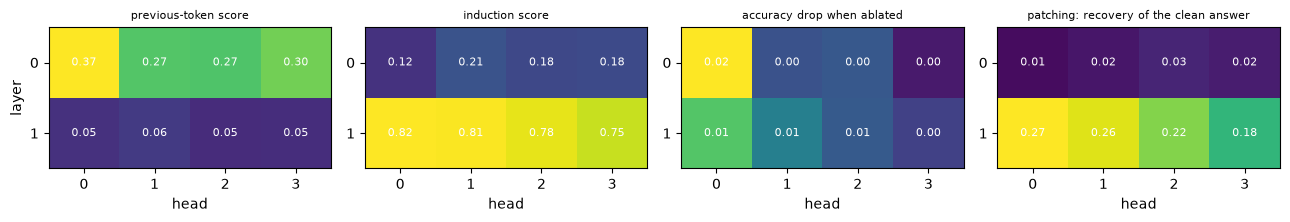

accuracy when ALL four layer-1 heads are ablated: 0.229; when ALL four layer-0 heads are ablated: 0.413
patching used 300 prompts the model solves; baseline accuracy on repeated tokens 0.946
previous-token score | layer 0: [0.37 0.27 0.27 0.3 ] | layer 1: [0.05 0.06 0.05 0.05]
induction score | layer 0: [0.12 0.21 0.18 0.18] | layer 1: [0.82 0.81 0.78 0.75]
accuracy drop when ablated | layer 0: [0.02 0.   0.   0.  ] | layer 1: [0.01 0.01 0.01 0.  ]
patching recovery | layer 0: [0.01 0.02 0.03 0.02] | layer 1: [0.27 0.26 0.22 0.18]


In [16]:
# 1) look at the attention patterns: previous-token score (query p attends to p-1) and induction score
#    (query p, inside the repeated block, attends to the token AFTER the earlier occurrence of the current token)
cache = {}
with torch.no_grad(): lm(tt, cache=cache)
prev_score, ind_score = np.zeros((2, H)), np.zeros((2, H))
for l in range(2):
    att = cache[l][0]                                                           # (B, H, T, T)
    for i in range(len(tt)):
        k = int(nn_[i]); qs = torch.arange(k, 2 * k - 1)                        # query positions in the repeated block (current token = t[q-k])
        ind_score[l] += (att[i][:, qs, qs - k + 1].mean(1)).numpy() / len(tt)
        prev_score[l] += (att[i][:, torch.arange(1, L), torch.arange(0, L - 1)].mean(1)).numpy() / len(tt)

# 2) ablate each head (replace its output by its mean over the batch) and measure accuracy on the repeated tokens
base = repeat_acc(); abl = np.zeros((2, H))
for l in range(2):
    for h in range(H):
        mean_z = cache[l][1][:, h].mean(0, keepdim=True).expand(len(tt), -1, -1)
        abl[l, h] = base - repeat_acc({(l, h): mean_z})

# 3) activation patching: clean prompt  [a0..a7][a0..a7]  vs corrupted prompt where the token after a_j in the FIRST block is changed
def patching(n=300, seed=7):
    g = torch.Generator().manual_seed(seed); rec = np.zeros((2, H)); used = 0
    for _ in range(n):
        a = torch.randperm(V, generator=g)[:9]                               # 9 distinct symbols: a0..a7 plus a spare one
        clean = torch.cat([a[:8], a[:8], torch.randint(0, V, (8,), generator=g)])[None]
        j = int(torch.randint(1, 7, (1,), generator=g)); q = 8 + j              # query position: token a_j in the repeat; the answer is a_{j+1}
        corrupt = clean.clone(); corrupt[0, j + 1] = a[8]                      # in the first block, a_{j+1} -> spare symbol
        ans_clean, ans_corr = int(a[j + 1]), int(a[8])
        cc, cr = {}, {}
        with torch.no_grad():
            lc = lm(clean, cache=cc)[0, q]; lr_ = lm(corrupt, cache=cr)[0, q]
            gap = lambda lg: float(lg[ans_clean] - lg[ans_corr])
            if gap(lc) - gap(lr_) < 1.0: continue                              # skip prompts the model does not solve
            used += 1
            for l in range(2):
                for h in range(H):
                    lp = lm(corrupt, edit={(l, h): cc[l][1][:, h]})[0, q]       # patch ONE head's output from the clean run
                    rec[l, h] += (gap(lp) - gap(lr_)) / (gap(lc) - gap(lr_))
    return rec / max(used, 1), used
rec, used = patching()

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, (name, M_) in zip(axes, [("previous-token score", prev_score), ("induction score", ind_score), ("accuracy drop when ablated", abl), ("patching: recovery of the clean answer", rec)]):
    im = ax.imshow(M_, cmap="viridis", vmin=0); ax.set_title(name, fontsize=8); ax.set_xlabel("head"); ax.set_yticks([0, 1]); ax.set_xticks(range(H)); ax.grid(False)
    for (r_, c_), v in np.ndenumerate(M_): ax.text(c_, r_, f"{v:.2f}", ha="center", va="center", color="w", fontsize=8)
axes[0].set_ylabel("layer"); plt.tight_layout(); plt.show()
all1 = {(1, h): cache[1][1][:, h].mean(0, keepdim=True).expand(len(tt), -1, -1) for h in range(H)}
all0 = {(0, h): cache[0][1][:, h].mean(0, keepdim=True).expand(len(tt), -1, -1) for h in range(H)}
print(f"accuracy when ALL four layer-1 heads are ablated: {repeat_acc(all1):.3f}; when ALL four layer-0 heads are ablated: {repeat_acc(all0):.3f}")
print(f"patching used {used} prompts the model solves; baseline accuracy on repeated tokens {base:.3f}")
for name, M_ in [("previous-token score", prev_score), ("induction score", ind_score), ("accuracy drop when ablated", abl), ("patching recovery", rec)]:
    print(name, "| layer 0:", np.round(M_[0], 2), "| layer 1:", np.round(M_[1], 2))

**Reading.** The toy learns the task: accuracy on repeated tokens 0.946 against 0.042 for chance, and the loss falls from 3.42 to 0.14 in 500 steps. The heads are as the induction story predicts. In layer 0 every head puts some attention on the previous token (scores 0.27 to 0.37, against 0.05 in layer 1), and in layer 1 all four heads have an induction score of 0.75 to 0.82 against 0.12 to 0.21 in layer 0. The causal tests show something less tidy than the textbook picture: ablating any single head costs at most 2 points of accuracy, but ablating all four layer-1 heads drops accuracy to 0.229 and ablating all four layer-0 heads to 0.413. The four induction heads are **redundant copies**, so single-head ablation underestimates their role. Activation patching agrees: patching one layer-1 head from the clean run restores 18 to 27 % of the clean answer (roughly 93 % over the four) while a single layer-0 head restores at most 3 %, because the previous-token information is spread across four heads. This is the main practical lesson of circuit analysis: causal evidence needs interventions designed for the structure (here, whole groups of heads). The toy has an easy, clean circuit by design; real language models have many overlapping circuits, and results there are partial. One training run.

### 8.2 Sparse autoencoders and superposition

A network often needs to represent more features than it has dimensions. **Superposition** (Elhage et al., [2022](https://transformer-circuits.pub/2022/toy_model/index.html)) is the observation that it can do so by storing features as *non-orthogonal directions*, relying on the fact that few features are active at the same time. The consequence for interpretability is that **individual neurons rarely mean one thing**: they mix several features ("polysemanticity"). A **sparse autoencoder** (SAE) is a remedy tried on real models by Cunningham et al. ([2023](https://arxiv.org/abs/2309.08600)) and Bricken et al. ([2023](https://transformer-circuits.pub/2023/monosemantic-features/index.html)): train a wide autoencoder on a layer's activations with a penalty (the $L_1$ norm, the sum of absolute values) that makes the code **sparse**, and hope each code unit lands on one true feature. Scaled versions on frontier models are an active research area; they are promising, but their reliability and usefulness are debated.

Our toy is the smallest honest test: 12 hidden "true" features, each a unit direction in only 5 dimensions (chosen from 2000 random draws to be as spread out as possible, so that no two are almost parallel), each active about 8 % of the time with a random strength. We observe only the 5-dimensional sum. Can an SAE with 24 units find the 12 directions? Principal component analysis (PCA) is the linear baseline: it has only 5 axes, so it cannot.

In [17]:
torch.manual_seed(0); r = np.random.default_rng(0)
NF, DD, NL = 12, 5, 24
best = None
for _ in range(2000):                                                                          # keep the best-spread draw
    cand = r.normal(size=(NF, DD)); cand /= np.linalg.norm(cand, axis=1, keepdims=True)
    worst = np.abs(cand @ cand.T - np.eye(NF)).max()
    if best is None or worst < best[0]: best = (worst, cand)
Fdir = best[1]                                                                                 # true feature directions
def sample_acts(n, seed):
    rr = np.random.default_rng(seed)
    active = rr.random((n, NF)) < 0.08
    return ((active * rr.uniform(0.5, 1.5, (n, NF))) @ Fdir).astype(np.float32), active
Xa, act_true = sample_acts(40000, 1)
print(f"mean number of active true features per sample: {act_true.sum(1).mean():.2f}; max |cosine| between two true directions: {np.abs(Fdir @ Fdir.T - np.eye(NF)).max():.2f}")

class SAE(nn.Module):
    def __init__(s):
        super().__init__(); s.enc = nn.Linear(DD, NL); s.dec = nn.Parameter(torch.randn(NL, DD) * 0.3)
    def forward(s, x):
        z = F.relu(s.enc(x)); d = s.dec / s.dec.norm(dim=1, keepdim=True); return z @ d, z, d

def train_sae(l1, steps=2500):
    torch.manual_seed(0); sae = SAE(); opt = torch.optim.Adam(sae.parameters(), 3e-3); Xt_ = torch.tensor(Xa)
    for step in range(steps):
        b = Xt_[torch.randint(0, len(Xt_), (512,))]; rec, z, d = sae(b)
        loss = F.mse_loss(rec, b) + l1 * z.abs().sum(1).mean(); opt.zero_grad(); loss.backward(); opt.step()
    return sae

t0 = time.time(); out = []
Xte_sae = torch.tensor(sample_acts(5000, 2)[0])
for l1 in [0.0, 0.1, 0.2, 0.4]:
    sae = train_sae(l1)
    with torch.no_grad(): rec, z, d = sae(Xte_sae)
    cos = np.abs(Fdir @ d.numpy().T)                                              # (true feature, SAE unit)
    best = cos.max(1)
    out.append(dict(l1_penalty=l1, features_recovered=int((best > 0.95).sum()), mean_best_cosine=best.mean(), active_units_per_sample=float((z > 1e-3).float().sum(1).mean()),
                    reconstruction_R2=1 - float(F.mse_loss(rec, Xte_sae) / Xte_sae.var())))
print(pd.DataFrame(out).round(3).to_string(index=False)); print(f"SAE training: {time.time() - t0:.0f} s")
# PCA baseline: how well do 5 orthogonal axes line up with the 12 true directions?
U = np.linalg.svd(Xa, full_matrices=False)[2]
print(f"PCA (5 axes): features with a |cosine| > 0.95 axis = {(np.abs(Fdir @ U.T).max(1) > 0.95).sum()}, mean best cosine {np.abs(Fdir @ U.T).max(1).mean():.2f}")

mean number of active true features per sample: 0.96; max |cosine| between two true directions: 0.73


 l1_penalty  features_recovered  mean_best_cosine  active_units_per_sample  reconstruction_R2
        0.0                   1             0.817                   15.380              1.000
        0.1                   9             0.953                    2.835              0.889
        0.2                  11             0.987                    1.638              0.707
        0.4                   9             0.969                    0.744              0.300
SAE training: 6 s
PCA (5 axes): features with a |cosine| > 0.95 axis = 0, mean best cosine 0.75


**Reading.** With no sparsity penalty the autoencoder reconstructs perfectly (R2 = 1.00) but uses 15 of its 24 units for every sample and aligns with only 1 of the 12 true directions (mean best cosine 0.82): reconstruction alone does not make features appear. PCA, with its 5 orthogonal axes, aligns with none (mean best cosine 0.75). With an L1 penalty of 0.1 the code is sparse (2.8 active units) and 9 of 12 true directions are recovered with cosine above 0.95; at 0.2 it is 11 of 12 (mean best cosine 0.99) at the price of reconstruction quality (R2 0.71); at 0.4 reconstruction collapses (R2 0.30) and recovery falls to 9. So there is a real trade-off between **sparsity** and **fidelity**, and the best penalty is found by looking at ground truth, which for a real language model we do not have. The toy is also easy by design: the directions were chosen to be well spread, features are independent and about one is active at a time, and we tuned the penalty list on this very data. Real activations have correlated, hierarchical, continuous features, which is why the large-scale results (Bricken et al., Cunningham et al.) need millions of units and careful human and automated inspection, and why the question of how well they capture a model's computation is still open. Single seed; the number recovered can change by one between runs and machines.

## 9. Limits and misuse of explanations

What the measurements above warn about, collected in one place.

* **An explanation describes the model, not the world.** The glucose example showed a feature receiving credit without having any causal effect. Attribution answers "what does the model use", and only an intervention or domain knowledge answers "what would change the outcome".
* **Many methods look right and are not.** Section 4.1 is the lesson of Adebayo et al.: an attractive map is not evidence. Always run a randomisation test and a deletion test before trusting a method on a new model, and compare to a model-free baseline such as edges or brightness.
* **Different methods disagree, and the disagreement is not noise only.** Saliency, SmoothGrad, integrated gradients and Grad-CAM gave different maps for the same image and prediction (the correlation matrix in section 4). Choosing the one that "looks best" is **confirmation bias** dressed as analysis.
* **Faithfulness tests have their own artefacts.** Deleting pixels creates images the model never saw (an out-of-distribution input), which can change its output for reasons unrelated to the deleted content. Hooker et al. ([2019](https://arxiv.org/abs/1806.10758)) address this by retraining after removal (ROAR, RemOve And Retrain).
* **Baselines and correlated features change the answer.** Integrated gradients and Shapley values depend on the choice of baseline or background. With correlated features, credit is shared in ways that depend on whether you break the correlation (interventional) or respect it (conditional).
* **Probes show presence, not use; attention shows routing, not reasons; a circuit found in a toy may not exist at scale.** Mechanistic results on large models are partial and hand-checked.
* **Explanations can be used to launder a decision.** A post-hoc story attached to a model that was never designed to be understood gives false assurance, and an explanation can be shown to a person who then trusts the model *more* than its accuracy justifies. Rudin ([2019](https://arxiv.org/abs/1811.10154)) recommends stopping explaining black boxes for high-stakes decisions and using interpretable models where they are accurate enough. Section 2 is a small instance of that argument.
* **Explanations can be gamed.** Slack et al. ([2020](https://arxiv.org/abs/1911.02508)) built classifiers that behave discriminatorily on real inputs but look innocent to LIME and SHAP, because those methods query the model on unrealistic perturbed inputs that the classifier can recognise.

**A practical protocol.** (1) Say what decision the explanation supports and who reads it. (2) Prefer an interpretable model when it is accurate enough. (3) For a black box, use at least two methods and a model-free baseline. (4) Run a randomisation test and a deletion or retraining test. (5) Try to **break your own explanation** by planting a known flaw, as in section 5. (6) Report explanations as hypotheses about the model, with their uncertainty, and verify them by intervention where you can.

## Key takeaways

* **Interpretable by design versus post-hoc, global versus local, explanation versus causal claim.** Keep these three distinctions in every discussion; most confusion comes from mixing them.
* **A readable model is a yardstick.** On a task with a known rule, the logistic regression and the tree gave the baseline against which attribution methods could be scored.
* **Shapley values are exact but exponential; sampling and gradients are the practical routes.** Integrated gradients and Shapley satisfy completeness, which we verified numerically; gradient times input does not. LIME depends on a kernel-width choice and on random perturbations, so check its stability.
* **Never trust a map without a test.** The randomisation test and the deletion curve separate methods that reflect the model from methods that reflect the image; a model-free baseline shows what "good" has to beat.
* **Attribution can find a planted shortcut**, and the measured accuracy drop when the cue is removed shows how much damage it does. The fix is in the data (decorrelate the cue), not in the explanation.
* **Attention weights are not explanations.** Gradient and occlusion rankings are closer to what the model uses; probes show what is linearly readable, not what is used.
* **Mechanistic interpretability makes causal claims by intervention.** Ablation and activation patching located the induction circuit in a toy; sparse autoencoders can recover features stored in superposition in a toy, and whether this scales is an open research question.
* **Explanations have limits and can be misused.** Treat them as hypotheses about the model, test them, and prefer interpretable models for high-stakes decisions.

## Exercises

1. In section 2 add a second decoy `glucose2` that is a noisy copy of `age`. How do Shapley values and permutation importance split credit between correlated features? Does the exact Shapley sum still equal $f(x) - \mathbb{E}[f]$?
2. Change the Shapley background from 100 random rows to a single row (the mean). How different are the values? What does that say about "the" Shapley value?
3. In section 3 implement LIME with discretised features (bins) instead of Gaussian perturbations. Is it more or less stable across seeds?
4. Add **gradient times input** and **SmoothGrad** to the sanity check of section 4.1. Which methods pass? Try randomising only `c1` (bottom-up) instead of top-down.
5. In section 4.2 replace the black fill by the average of the image and re-measure the deletion AUCs. Do the rankings change? Why does the fill matter?
6. In section 5 shrink the patch to 2 by 2 pixels, or give it a 90 % correlation with the label instead of 100 %. How does the accuracy drop when the cue is removed, and does the pointing game still find it?
7. In section 6 try the Grad-CAM on a different layer (`layer3`). How does the map change, and what happens to the deletion AUC?
8. In section 7.2 use the attention from the **first layer** instead of the last. Does it correlate better with occlusion? Then average attention over only the most important head.
9. In section 8.1 train for 100 steps and look at the induction score again. At what step do the heads appear (hint: record the loss curve and the scores every 50 steps)?
10. In section 8.2 change the number of true features from 12 to 6 and then 30. How does the SAE recovery change, and at what point does it stop working?

## References

* Rudin, C. (2019). Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead. *Nature Machine Intelligence* 1, 206-215. arXiv:1811.10154: https://arxiv.org/abs/1811.10154
* Ribeiro, M. T., Singh, S. and Guestrin, C. (2016). "Why should I trust you?": explaining the predictions of any classifier (LIME). arXiv:1602.04938: https://arxiv.org/abs/1602.04938
* Lundberg, S. M. and Lee, S.-I. (2017). A unified approach to interpreting model predictions (SHAP). arXiv:1705.07874: https://arxiv.org/abs/1705.07874
* Sundararajan, M., Taly, A. and Yan, Q. (2017). Axiomatic attribution for deep networks (integrated gradients). arXiv:1703.01365: https://arxiv.org/abs/1703.01365
* Simonyan, K., Vedaldi, A. and Zisserman, A. (2014). Deep inside convolutional networks: visualising image classification models and saliency maps. arXiv:1312.6034: https://arxiv.org/abs/1312.6034
* Smilkov, D. et al. (2017). SmoothGrad: removing noise by adding noise. arXiv:1706.03825: https://arxiv.org/abs/1706.03825
* Selvaraju, R. R. et al. (2017). Grad-CAM: visual explanations from deep networks via gradient-based localization. *ICCV*. arXiv:1610.02391: https://arxiv.org/abs/1610.02391
* Adebayo, J. et al. (2018). Sanity checks for saliency maps. *NeurIPS*. arXiv:1810.03292: https://arxiv.org/abs/1810.03292
* Samek, W. et al. (2017). Evaluating the visualization of what a deep neural network has learned. arXiv:1509.06321: https://arxiv.org/abs/1509.06321
* Petsiuk, V., Das, A. and Saenko, K. (2018). RISE: randomized input sampling for explanation of black-box models. arXiv:1806.07421: https://arxiv.org/abs/1806.07421
* Zhang, J. et al. (2018). Top-down neural attention by excitation backprop (the pointing game). *IJCV*. arXiv:1608.00507: https://arxiv.org/abs/1608.00507
* Hooker, S. et al. (2019). A benchmark for interpretability methods in deep neural networks (ROAR). arXiv:1806.10758: https://arxiv.org/abs/1806.10758
* Slack, D. et al. (2020). Fooling LIME and SHAP: adversarial attacks on post hoc explanation methods. *AIES*. arXiv:1911.02508: https://arxiv.org/abs/1911.02508
* Jain, S. and Wallace, B. C. (2019). Attention is not explanation. *NAACL*. arXiv:1902.10186: https://arxiv.org/abs/1902.10186
* Wiegreffe, S. and Pinter, Y. (2019). Attention is not not explanation. *EMNLP*. arXiv:1908.04626: https://arxiv.org/abs/1908.04626
* Hewitt, J. and Liang, P. (2019). Designing and interpreting probes with control tasks. *EMNLP*. arXiv:1909.03368: https://arxiv.org/abs/1909.03368
* Olsson, C. et al. (2022). In-context learning and induction heads. *Transformer Circuits Thread*: https://transformer-circuits.pub/2022/in-context-learning-and-induction-heads/index.html
* Elhage, N. et al. (2022). Toy models of superposition. *Transformer Circuits Thread*: https://transformer-circuits.pub/2022/toy_model/index.html
* Bricken, T. et al. (2023). Towards monosemanticity: decomposing language models with dictionary learning. *Transformer Circuits Thread*: https://transformer-circuits.pub/2023/monosemantic-features/index.html
* Cunningham, H. et al. (2023). Sparse autoencoders find highly interpretable features in language models. arXiv:2309.08600: https://arxiv.org/abs/2309.08600
* He, K. et al. (2015). Deep residual learning for image recognition. arXiv:1512.03385: https://arxiv.org/abs/1512.03385
* Sanh, V. et al. (2019). DistilBERT, a distilled version of BERT. arXiv:1910.01108: https://arxiv.org/abs/1910.01108
* Xiao, H., Rasul, K. and Vollgraf, R. (2017). Fashion-MNIST. arXiv:1708.07747: https://arxiv.org/abs/1708.07747 (MIT licence; [dataset card](https://huggingface.co/datasets/zalando-datasets/fashion_mnist))
* Casanueva, I. et al. (2020). Efficient intent detection with dual sentence encoders (Banking77). arXiv:2003.04807: https://arxiv.org/abs/2003.04807 (CC BY 4.0; [dataset card](https://huggingface.co/datasets/PolyAI/banking77))
* Tools: [SHAP library](https://github.com/shap/shap), [Captum (interpretability for PyTorch)](https://captum.ai), [TransformerLens](https://github.com/TransformerLensOrg/TransformerLens), [scikit-image data](https://scikit-image.org/docs/stable/api/skimage.data.html)
* Sibling course: [Python 1001, AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/)

In [18]:
print(f"total notebook run time: {(time.time() - T_START) / 60:.1f} minutes")

total notebook run time: 2.5 minutes
